# EDA descriptivo — Registros RIPS 2021 (`Registros copia.csv`)

**Objetivo.** Documentar de forma descriptiva y reproducible la estructura, la calidad y la distribución de un archivo de registros RIPS del año 2021 con seis columnas: `Departamento`, `Municipio`, `Año`, `TipoAtencion`, `Diagnostico` y `NumeroAtenciones`.

**Alcance.** Exclusivamente exploratorio y descriptivo: conteos, sumas, porcentajes, controles de calidad y cruces. No hay inferencia, modelado, tasas poblacionales ni análisis causal.

**Fuentes usadas**

| Fuente | Uso |
|---|---|
| `esquema_y_calidad.csv` | Estructura y calidad por columna |
| `estadisticas_numero_atenciones.csv` | Estadísticos de `NumeroAtenciones` |
| `validacion_totales.csv` | 30 comprobaciones técnicas de consistencia |
| `resumen_hallazgos.md` | Hallazgos agregados y limitaciones declaradas |
| `EDA2021-copia.ipynb` | Solo como guía de organización (el dataset de esa referencia es otro y no se reutilizan sus variables ni resultados) |
| `Registros copia.csv` (local) | Necesario únicamente para las celdas marcadas **[CSV]** |

**Convención de etiquetas de origen** (aparece en cada resultado):

- **[ADJUNTO]**: cifra tomada tal cual de los archivos adjuntos.
- **[DERIVADO]**: aritmética simple sobre cifras adjuntas; se muestra la operación.
- **[CSV]**: se calcula únicamente al ejecutar el CSV local con DuckDB.

**Modos de ejecución.** *Modo A* (sin CSV): el notebook corre completo con los agregados adjuntos y omite las celdas **[CSV]**. *Modo B* (con CSV): además recalcula todo con DuckDB, genera tablas/figuras completas y concilia cada cifra con lo adjunto.

> **Importante.** No existe en los archivos disponibles un diccionario de datos. La definición operativa de las seis columnas, la unidad de observación y el significado de `NumeroAtenciones` **no están confirmados**. Todo lo que sigue debe leerse con esa salvedad.

## 1. Qué está confirmado y qué no

| Aspecto | Estado | Fuente |
|---|---|---|
| Tamaño (3,567,656 filas × 6 columnas) y encabezados | Observado | Adjuntos |
| Definición de cada columna | **No confirmada** | No hay diccionario |
| Unidad de observación (¿persona, episodio, fila agregada?) | **No confirmada** | `resumen_hallazgos.md` |
| `NumeroAtenciones` como total oficial de prestaciones | **No confirmado** | `resumen_hallazgos.md` |
| `Departamento`/`Municipio` como residencia, ocurrencia o lugar de prestación | **No determinado** | `resumen_hallazgos.md` |
| Etiquetas de `Diagnostico` y `TipoAtencion` frente a un catálogo | **No validadas** | `resumen_hallazgos.md` |
| Cobertura temporal | Solo `Año` = 2021 (1 valor distinto) | `esquema_y_calidad.csv` |

Por eso se distingue siempre entre **filas del archivo** (conteo de registros) y **suma de `NumeroAtenciones`** (suma de un campo numérico cuyo significado no está documentado).

## 2. Bibliotecas y configuración

La ruta del CSV y las carpetas de salida son configurables mediante variables de entorno (`RIPS_CSV_PATH`, `RIPS_OUT_DIR`, `RIPS_DB_PATH`) o editando la celda. No hay rutas absolutas del equipo del autor.

Dependencias: `pip install duckdb pandas matplotlib` (DuckDB solo es obligatorio en modo B).

In [3]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

try:
    from IPython.display import display
except ImportError:  # ejecución fuera de Jupyter
    display = print

try:
    import duckdb
except ImportError:
    duckdb = None

# ----------------------------- CONFIGURACIÓN -----------------------------
# Ruta del CSV (relativa por defecto: coloque el archivo junto al notebook o use la variable de entorno).
_env_path = os.environ.get("RIPS_CSV_PATH")
if _env_path:
    _csv_path_str = os.path.expanduser(_env_path)
else:
    # Intenta ruta relativa predeterminada en data/raw primero
    _csv_path_str = "data/raw/Registros copia.csv"
    if not Path(_csv_path_str).is_file():
        # Si no existe, intenta junto al notebook
        alt_str = "Registros copia.csv"
        if Path(alt_str).is_file():
            _csv_path_str = alt_str
        else:
            # Solicita ruta interactiva si ninguna ruta funciona
            print(f"No se encontró archivo CSV en: {_csv_path_str}")
            print(f"Ruta alternativa probada: {alt_str}")
            # Primer intento interactivo
            _respuesta = input("Introduce la ruta del archivo CSV (o deja vacío para modo A sin CSV): ")
            _respuesta = _respuesta.strip() if _respuesta else ""
            if _respuesta == "":
                print("Modo A seleccionado: análisis con agregados adjuntos.")
                _csv_path_str = "data/raw/Registros copia.csv"  # no importa, modo A prevalecerá
            else:
                _respuesta = os.path.expanduser(_respuesta)
                if Path(_respuesta).is_file():
                    _csv_path_str = _respuesta
                    print(f"Archivo CSV asignado: {_respuesta}")
                else:
                    print(f"Advertencia: ruta no válida o archivo no encontrado: {_respuesta}")
                    # Segundo intento interactivo
                    _respuesta2 = input("Segunda ruta (o vacío para modo A): ")
                    _respuesta2 = _respuesta2.strip() if _respuesta2 else ""
                    if _respuesta2 == "":
                        print("Modo A seleccionado: análisis con agregados adjuntos.")
                        _csv_path_str = "data/raw/Registros copia.csv"
                    else:
                        _respuesta2 = os.path.expanduser(_respuesta2)
                        if Path(_respuesta2).is_file():
                            _csv_path_str = _respuesta2
                            print(f"Archivo CSV asignado (segunda ruta): {_respuesta2}")
                        else:
                            print(f"Advertencia: segunda ruta también inválida: {_respuesta2}")
                            print("Se continúa en modo A sin CSV.")
                            _csv_path_str = "data/raw/Registros copia.csv"

CSV_PATH = Path(_csv_path_str)
if CSV_PATH.is_file():
    print(f"Archivo CSV encontrado: {str(CSV_PATH)}")
else:
    print(f"Archivo CSV NO encontrado en: {str(CSV_PATH)}")
    print(f"Ruta intenta: {str(CSV_PATH.absolute()) if CSV_PATH.is_absolute() else str(CSV_PATH)}")
    if not CSV_PATH.is_file():
        # Si el archivo no existe, permitir continuar en modo A con advertencia
        print("Nota: se continuará en modo A (agregados adjuntos) si no se corrige la ruta.")
# Carpeta donde se guardan tablas completas y figuras generadas en modo B.
DIR_SALIDAS = Path(os.environ.get("RIPS_OUT_DIR", "salidas_eda"))
# ':memory:' (por defecto) o una ruta a un archivo .duckdb para persistir la tabla cargada.
DB_PATH = os.environ.get("RIPS_DB_PATH", ":memory:")
GUARDAR_TABLAS = True
GUARDAR_FIGURAS = True
TOP_N = 20  # solo limita la PRESENTACIÓN en gráficos; las tablas guardadas conservan todas las categorías
# --------------------------------------------------------------------------

COLUMNAS = ["Departamento", "Municipio", "Año", "TipoAtencion", "Diagnostico", "NumeroAtenciones"]
DIMENSIONES = COLUMNAS[:5]

CSV_DISPONIBLE = CSV_PATH.is_file()
if CSV_DISPONIBLE and duckdb is None:
    raise ImportError("Se encontró el CSV pero falta DuckDB. Instale con: pip install duckdb")

(DIR_SALIDAS / "figuras").mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 70)
pd.set_option("display.width", 180)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

print("Modo de ejecución:", "B (con CSV local)" if CSV_DISPONIBLE else "A (solo agregados adjuntos)")
if not CSV_DISPONIBLE:
    print(f"  CSV no encontrado en: {CSV_PATH}  -> las celdas [CSV] se omitirán.")


No se encontró archivo CSV en: data/raw/Registros copia.csv
Ruta alternativa probada: Registros copia.csv


Archivo CSV asignado: /run/media/Jooicy/46F07048F0703FEB/personal/carrera/7/ia/proyecto-mortalidad/data/raw/Registros copia.csv
Archivo CSV encontrado: /run/media/Jooicy/46F07048F0703FEB/personal/carrera/7/ia/proyecto-mortalidad/data/raw/Registros copia.csv
Modo de ejecución: B (con CSV local)


In [5]:
# Modo de ejecucion detectado (ajuste R1)
# Reutiliza la configuracion canonica del notebook: CSV_PATH, CSV_DISPONIBLE
# (definidas en la celda de configuracion, index 3)
# No redefinir la ruta: usamos las variables ya cargadas.

if CSV_DISPONIBLE:
    MODO = 'B (con CSV local): analisis completo con DuckDB; celdas [CSV] ejecutables'
else:
    MODO = 'A (solo agregados adjuntos): resultados de archivo guardados sin recalcular a nivel fila'

print('----------------------------------------------------------------')
print('MODO ACTIVO:', MODO)
print('Ruta CSV canonica:', str(CSV_PATH) if CSV_DISPONIBLE else 'No encontrado (ver variable RIPS_CSV_PATH)')
print('Nota: Modo A no equivale a recalcular los datos originales; solo usa los agregados adjuntos.')
print('----------------------------------------------------------------')


----------------------------------------------------------------
MODO ACTIVO: B (con CSV local): analisis completo con DuckDB; celdas [CSV] ejecutables
Ruta CSV canonica: /run/media/Jooicy/46F07048F0703FEB/personal/carrera/7/ia/proyecto-mortalidad/data/raw/Registros copia.csv
Nota: Modo A no equivale a recalcular los datos originales; solo usa los agregados adjuntos.
----------------------------------------------------------------


In [8]:
# ---------------------------- Funciones auxiliares ----------------------------
RECONC = []  # conciliación entre cifras recalculadas con el CSV y cifras adjuntas


def solo_con_csv():
    """Devuelve True si hay CSV; si no, avisa que la celda requiere el archivo local."""
    if not CSV_DISPONIBLE:
        print("[Requiere CSV local] Celda omitida en modo A. Defina CSV_PATH y vuelva a ejecutar.")
    return CSV_DISPONIBLE


def comparar(control, observado, esperado, tol=0.0):
    """Registra la comparación entre un valor recalculado y su valor adjunto."""
    ok = (observado == esperado) if tol == 0 else abs(float(observado) - float(esperado)) <= tol
    RECONC.append({"control": control, "recalculado_csv": observado,
                   "valor_adjunto": esperado, "coincide": "SÍ" if ok else "NO"})
    return bool(ok)


def guardar_tabla(df, nombre):
    if GUARDAR_TABLAS:
        df.to_csv(DIR_SALIDAS / f"{nombre}.csv", index=False, encoding="utf-8-sig")


def guardar_fig(fig, nombre):
    if GUARDAR_FIGURAS:
        fig.savefig(DIR_SALIDAS / "figuras" / f"{nombre}.png", dpi=120, bbox_inches="tight")


def miles(df, cols=None, dec=0):
    """Copia con columnas numéricas formateadas con separador de miles (solo para mostrar)."""
    out = df.copy()
    for c in (cols or out.select_dtypes("number").columns):
        out[c] = out[c].map(lambda v: f"{v:,.{dec}f}" if pd.notna(v) else "")
    return out


def barh_top(df, col_cat, col_val, titulo, xlabel, n=TOP_N, col_pct=None, fname=None, wrap=48):
    """Barras horizontales Top-n con etiquetas de dato. Solo limita la presentación."""
    d = df.nlargest(n, col_val).iloc[::-1].reset_index(drop=True)
    etiquetas = [s if len(s) <= wrap else s[: wrap - 1] + "…" for s in d[col_cat].astype(str)]
    fig, ax = plt.subplots(figsize=(10, max(3.5, 0.34 * len(d) + 1.6)))
    ax.barh(range(len(d)), d[col_val], color="steelblue")
    ax.set_yticks(range(len(d)))
    ax.set_yticklabels(etiquetas, fontsize=8)
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:,.0f}"))
    for i, v in enumerate(d[col_val]):
        txt = f"{v:,.0f}" + (f" ({d[col_pct].iloc[i]:.2f}%)" if col_pct else "")
        ax.text(v, i, " " + txt, va="center", fontsize=8)
    ax.margins(x=0.22)
    ax.set_title(titulo, fontsize=11)
    ax.set_xlabel(xlabel)
    fig.tight_layout()
    if fname:
        guardar_fig(fig, fname)
    plt.show()


def concentracion(df, ks=(1, 5, 10, 20, 50, 100)):
    """% acumulado de filas y de suma de NumeroAtenciones que reúnen las k categorías principales
    (el ranking se calcula por separado para filas y para suma)."""
    r = df.sort_values("filas", ascending=False)["filas"].cumsum() / df["filas"].sum() * 100
    s_ = df["suma_atenciones"].fillna(0)
    s = df.assign(_s=s_).sort_values("_s", ascending=False)["_s"].cumsum() / s_.sum() * 100
    filas = [{"top_k": k, "pct_filas_acumulado": r.iloc[k - 1], "pct_suma_acumulado": s.iloc[k - 1]}
             for k in ks if k <= len(df)]
    return pd.DataFrame(filas)


def apilado_100(df, idx, col, val, titulo, xlabel, fname=None):
    """Barras horizontales apiladas al 100 % de `val` por `idx`, con segmentos `col`."""
    p = df.pivot_table(index=idx, columns=col, values=val, aggfunc="sum", fill_value=0)
    orden = p.sum(axis=1).sort_values(ascending=True).index
    p = p.loc[orden]
    pct = p.div(p.sum(axis=1), axis=0) * 100
    fig, ax = plt.subplots(figsize=(10, max(4, 0.32 * len(pct) + 1.8)))
    izq = np.zeros(len(pct))
    for c in pct.columns:
        ax.barh(range(len(pct)), pct[c], left=izq, label=str(c))
        izq += pct[c].values
    ax.set_yticks(range(len(pct)))
    ax.set_yticklabels([str(s)[:40] for s in pct.index], fontsize=8)
    ax.set_xlim(0, 100)
    ax.set_xlabel(xlabel)
    ax.set_title(titulo, fontsize=11)
    ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2)
    fig.tight_layout()
    if fname:
        guardar_fig(fig, fname)
    plt.show()

### 2.1 Resultados de referencia incorporados **[ADJUNTO]**

Las cifras de los archivos adjuntos se incorporan abajo como literales para que el notebook sea autocontenido. Cada cifra proviene de: `esquema_y_calidad.csv` (ESQUEMA), `estadisticas_numero_atenciones.csv` (STATS), `validacion_totales.csv` (VALIDACION) y `resumen_hallazgos.md` (el resto). No se agrega ningún valor que no esté en esos archivos.

In [9]:
# ======================= DATOS ADJUNTOS (transcritos tal cual) =======================
N_FILAS, N_COLS, SUMA_TOTAL = 3_567_656, 6, 345_993_084

# esquema_y_calidad.csv
ESQUEMA = pd.DataFrame(
    [
        ("Departamento",     "texto/categórico o mixto", 3567656, 3567656, 0, 0, 0,     0,   27,  23),
        ("Municipio",        "texto/categórico o mixto", 3567656, 3567656, 0, 0, 0,     0, 1066,  36),
        ("Año",              "entero",                   3567656, 3567656, 0, 0, 0,     0,    1,   4),
        ("TipoAtencion",     "texto/categórico o mixto", 3567656, 3567656, 0, 0, 0,     0,    4,  23),
        ("Diagnostico",      "texto/categórico o mixto", 3567656, 3567656, 0, 0, 0, 41794, 11873, 248),
        ("NumeroAtenciones", "entero",                   3567656, 3567656, 0, 0, 0,     0, 8605,   7),
    ],
    columns=["variable", "tipo_observado", "filas_totales", "no_vacios", "nulos", "cadenas_vacias",
             "solo_espacios", "espacios_externos", "valores_distintos", "longitud_maxima"],
)

# estadisticas_numero_atenciones.csv
STATS = {"filas_totales": 3567656, "valores_numericos_validos": 3567656, "no_convertibles_no_vacios": 0,
         "valores_cero": 0, "valores_negativos": 0, "minimo": 1, "maximo": 6371471, "suma": 345993084,
         "media": 96.98050596806418, "mediana": 3.0, "p25": 1.0, "p75": 10.0,
         "desviacion_estandar_muestral": 7263.750576156724}

# resumen_hallazgos.md — duplicados y espacios
DUP = {"exactos_excedentes": 1_183_160, "claves_repetidas_combinaciones": 906_363,
       "claves_repetidas_filas_excedentes": 1_183_160}

# resumen_hallazgos.md — TipoAtencion (solo se reportan dos de las cuatro categorías)
TIPO_REF = pd.DataFrame(
    [("CONSULTAS", 1_812_630, 50.81, 123_819_417, 35.79),
     ("PROCEDIMIENTOS DE SALUD", 1_016_433, 28.49, 216_021_749, 62.44)],
    columns=["TipoAtencion", "filas", "pct_filas_reportado", "suma_atenciones", "pct_suma_reportado"])

# resumen_hallazgos.md — etiquetas líderes (texto observado, sin recodificar)
TOP_DPTO_FILAS = ("25 - Cundinamarca", 468_637, 13.14)
TOP_MPIO_SUMA = ("11001 - Bogotá, D.C.", 42_305_118)
TOP_DX_FILAS = ("R104 - OTROS DOLORES ABDOMINALES Y LOS NO ESPECIFICADOS", 4_003, 0.112)

# resumen_hallazgos.md — cruces
CRUCES_REF = pd.DataFrame(
    [("cruce_departamento_tipo_atencion", "Departamento", "TipoAtencion", 108),
     ("cruce_tipo_atencion_diagnostico", "TipoAtencion", "Diagnostico", 39_011),
     ("cruce_departamento_diagnostico", "Departamento", "Diagnostico", 199_406),
     ("cruce_municipio_tipo_atencion", "Municipio", "TipoAtencion", 4_255)],
    columns=["cruce", "var_a", "var_b", "combinaciones_observadas"])

# validacion_totales.csv (control, resultado, observado, esperado)
VALIDACION = pd.DataFrame(
    [
        ("lectura_duckdb_vs_conteo_streaming", "OK", 3567656, 3567656),
        ("numero_atenciones_particion", "OK", 3567656, 3567656),
        ("frecuencia_Departamento", "OK", 3567656, 3567656),
        ("frecuencia_Municipio", "OK", 3567656, 3567656),
        ("frecuencia_Año", "OK", 3567656, 3567656),
        ("frecuencia_TipoAtencion", "OK", 3567656, 3567656),
        ("frecuencia_Diagnostico", "OK", 3567656, 3567656),
        ("cruce_departamento_tipo_atencion", "OK", 3567656, 3567656),
        ("cruce_tipo_atencion_diagnostico", "OK", 3567656, 3567656),
        ("cruce_departamento_diagnostico", "OK", 3567656, 3567656),
        ("cruce_municipio_tipo_atencion", "OK", 3567656, 3567656),
        ("suma_atenciones_departamento", "OK", 345993084, 345993084),
        ("suma_numericos_frecuencias_anio", "OK", 3567656, 3567656),
        ("suma_atenciones_frecuencias_anio", "OK", 345993084, 345993084),
        ("suma_numericos_frecuencias_departamento", "OK", 3567656, 3567656),
        ("suma_atenciones_frecuencias_departamento", "OK", 345993084, 345993084),
        ("suma_numericos_frecuencias_diagnostico", "OK", 3567656, 3567656),
        ("suma_atenciones_frecuencias_diagnostico", "OK", 345993084, 345993084),
        ("suma_numericos_frecuencias_municipio", "OK", 3567656, 3567656),
        ("suma_atenciones_frecuencias_municipio", "OK", 345993084, 345993084),
        ("suma_numericos_frecuencias_tipoatencion", "OK", 3567656, 3567656),
        ("suma_atenciones_frecuencias_tipoatencion", "OK", 345993084, 345993084),
        ("suma_numericos_cruce_departamento_diagnostico", "OK", 3567656, 3567656),
        ("suma_atenciones_cruce_departamento_diagnostico", "OK", 345993084, 345993084),
        ("suma_numericos_cruce_departamento_tipo_atencion", "OK", 3567656, 3567656),
        ("suma_atenciones_cruce_departamento_tipo_atencion", "OK", 345993084, 345993084),
        ("suma_numericos_cruce_municipio_tipo_atencion", "OK", 3567656, 3567656),
        ("suma_atenciones_cruce_municipio_tipo_atencion", "OK", 345993084, 345993084),
        ("suma_numericos_cruce_tipo_atencion_diagnostico", "OK", 3567656, 3567656),
        ("suma_atenciones_cruce_tipo_atencion_diagnostico", "OK", 345993084, 345993084),
    ],
    columns=["control", "resultado", "observado", "esperado"])

# Consistencia interna de la transcripción (no es una validación del dataset)
assert len(VALIDACION) == 30
assert (ESQUEMA["filas_totales"] == N_FILAS).all()
assert STATS["suma"] == SUMA_TOTAL and abs(STATS["media"] * N_FILAS - SUMA_TOTAL) < 1  # media x filas = suma
print("Datos adjuntos incorporados correctamente.")

Datos adjuntos incorporados correctamente.


## 3. Carga de datos con DuckDB **[CSV]**

El CSV se carga en una tabla de DuckDB (en memoria o en archivo) y **todo el análisis se hace con SQL**; nunca se convierte el archivo completo a un `DataFrame` de pandas. A pandas solo llegan tablas agregadas.

Decisiones de carga, alineadas con el análisis adjunto:

- Todas las columnas se leen como **texto** (`all_varchar`) para preservar códigos y etiquetas tal cual (sin perder ceros iniciales ni normalizar espacios).
- Se crea una vista `v` con dos columnas derivadas **solo para cálculo**: `n_atenciones` (`TRY_CAST` de `NumeroAtenciones` a entero) y `anio_num`. Los valores originales no se modifican.
- Nota técnica: con la configuración por defecto de DuckDB un campo vacío se lee como `NULL`, por lo que “nulos” y “cadenas vacías” pueden aparecer fusionados. El análisis adjunto reportó ambos en 0.

In [10]:
con = None
q = None

if solo_con_csv():
    con = duckdb.connect(DB_PATH)
    ruta_sql = str(CSV_PATH).replace("'", "''")
    con.execute(f"""
        CREATE OR REPLACE TABLE registros AS
        SELECT * FROM read_csv('{ruta_sql}', header = true, delim = ',', all_varchar = true)
    """)

    cols_obs = [r[0].lstrip("\ufeff") for r in con.execute("DESCRIBE registros").fetchall()]
    if cols_obs != COLUMNAS:
        raise ValueError(f"Encabezados inesperados.\n  Observados: {cols_obs}\n  Esperados:  {COLUMNAS}")

    con.execute("""
        CREATE OR REPLACE VIEW v AS
        SELECT *,
               TRY_CAST(trim("NumeroAtenciones") AS BIGINT) AS n_atenciones,
               TRY_CAST(trim("Año") AS INTEGER)             AS anio_num
        FROM registros
    """)

    def q(sql):
        """Ejecuta SQL en DuckDB y devuelve un DataFrame (solo para resultados agregados)."""
        return con.execute(sql).df()

    print("Tabla 'registros' creada. Encabezados verificados:", cols_obs)

Tabla 'registros' creada. Encabezados verificados: ['Departamento', 'Municipio', 'Año', 'TipoAtencion', 'Diagnostico', 'NumeroAtenciones']


## 4. Reconocimiento general

### 4.1 Estructura **[ADJUNTO]**

Según `esquema_y_calidad.csv` y `resumen_hallazgos.md`: delimitador coma, UTF-8, **3,567,656 filas × 6 columnas**. Tamaño del archivo original: 406.7 MiB.

In [11]:
estructura = ESQUEMA[["variable", "tipo_observado", "filas_totales", "valores_distintos", "longitud_maxima"]]
print(f"Dimensiones [ADJUNTO]: {N_FILAS:,} filas x {N_COLS} columnas")
display(miles(estructura, ["filas_totales", "valores_distintos", "longitud_maxima"]))

Dimensiones [ADJUNTO]: 3,567,656 filas x 6 columnas


,variable,tipo_observado,filas_totales,valores_distintos,longitud_maxima
0,Departamento,texto/categórico o mixto,"3,567,656",27,23
1,Municipio,texto/categórico o mixto,"3,567,656","1,066",36
2,Año,entero,"3,567,656",1,4
3,TipoAtencion,texto/categórico o mixto,"3,567,656",4,23
4,Diagnostico,texto/categórico o mixto,"3,567,656","11,873",248
5,NumeroAtenciones,entero,"3,567,656","8,605",7


**Lectura.** Cuatro variables son categóricas (texto) y dos (`Año`, `NumeroAtenciones`) son enteras convertibles. `Diagnostico` es la de mayor cardinalidad (11,873 etiquetas) y mayor longitud máxima (248 caracteres); `Municipio` tiene 1,066 etiquetas. `Año` tiene un único valor, por lo que **este archivo no permite análisis temporal**. El tipo “entero” de `NumeroAtenciones` describe el formato del campo, no su significado.

### 4.2 Verificación de estructura con el CSV local **[CSV]**

In [12]:
if solo_con_csv():
    n = q("SELECT count(*) AS n FROM registros")["n"].iloc[0]
    print(f"Filas: {n:,} | Columnas: {len(COLUMNAS)}")
    comparar("filas_totales", int(n), N_FILAS)
    comparar("columnas", len(COLUMNAS), N_COLS)
    display(q("DESCRIBE registros")[["column_name", "column_type"]])
    print("(No se muestran filas individuales: el EDA trabaja con agregados.)")

Filas: 3,567,656 | Columnas: 6


,column_name,column_type
0,Departamento,VARCHAR
1,Municipio,VARCHAR
2,Año,VARCHAR
3,TipoAtencion,VARCHAR
4,Diagnostico,VARCHAR
5,NumeroAtenciones,VARCHAR


(No se muestran filas individuales: el EDA trabaja con agregados.)


## 5. Calidad de datos

Todas las comprobaciones son exploratorias. **No se elimina, filtra ni corrige ningún registro.**

### 5.1 Nulos, vacíos y espacios **[ADJUNTO]**

In [13]:
calidad = ESQUEMA[["variable", "filas_totales", "nulos", "cadenas_vacias", "solo_espacios", "espacios_externos"]].copy()
calidad["pct_con_espacios_externos"] = calidad["espacios_externos"] / calidad["filas_totales"] * 100  # [DERIVADO]
display(miles(calidad, ["filas_totales", "nulos", "cadenas_vacias", "solo_espacios", "espacios_externos"])
        .assign(pct_con_espacios_externos=calidad["pct_con_espacios_externos"].map("{:.2f}%".format)))

,variable,filas_totales,nulos,cadenas_vacias,solo_espacios,espacios_externos,pct_con_espacios_externos
0,Departamento,"3,567,656",0,0,0,0,0.00%
1,Municipio,"3,567,656",0,0,0,0,0.00%
2,Año,"3,567,656",0,0,0,0,0.00%
3,TipoAtencion,"3,567,656",0,0,0,0,0.00%
4,Diagnostico,"3,567,656",0,0,0,"41,794",1.17%
5,NumeroAtenciones,"3,567,656",0,0,0,0,0.00%


**Lectura.** No se reportan nulos, cadenas vacías ni valores solo-espacios en ninguna de las seis columnas. La única incidencia es en `Diagnostico`: **41,794 valores con espacios externos** (≈1.17 % de las filas **[DERIVADO]** 41,794 / 3,567,656). Se preservaron sin normalizar, de modo que dos etiquetas que difieran solo en espacios aparecen como categorías distintas en las frecuencias. El efecto sobre el número de categorías se mide en 5.5 (requiere CSV).

### 5.2 `Año` **[ADJUNTO]**

3,567,656 enteros convertibles; 0 no convertibles; mínimo 2021, máximo 2021, 1 valor distinto. El archivo corresponde a un único año.

### 5.3 `NumeroAtenciones`: validez y distribución **[ADJUNTO]**

In [14]:
tabla_stats = pd.DataFrame({"estadístico": ["Filas totales", "Valores numéricos válidos", "No convertibles (no vacíos)",
                                            "Ceros", "Negativos", "Mínimo", "P25", "Mediana", "P75", "Media",
                                            "Desviación estándar muestral", "Máximo", "Suma"],
                            "valor": [STATS["filas_totales"], STATS["valores_numericos_validos"],
                                      STATS["no_convertibles_no_vacios"], STATS["valores_cero"],
                                      STATS["valores_negativos"], STATS["minimo"], STATS["p25"], STATS["mediana"],
                                      STATS["p75"], STATS["media"], STATS["desviacion_estandar_muestral"],
                                      STATS["maximo"], STATS["suma"]]})
display(tabla_stats.assign(valor=tabla_stats["valor"].map(lambda v: f"{v:,.2f}" if isinstance(v, float) else f"{v:,}")))

# [DERIVADO] razones simples a partir de las cifras anteriores
print(f"Media / mediana            = {STATS['media'] / STATS['mediana']:.1f}")
print(f"Desv. estándar / media     = {STATS['desviacion_estandar_muestral'] / STATS['media']:.1f}")
print(f"Máximo / suma total        = {STATS['maximo'] / STATS['suma'] * 100:.2f} %  (una sola fila)")

,estadístico,valor
0,Filas totales,"3,567,656.00"
1,Valores numéricos válidos,"3,567,656.00"
2,No convertibles (no vacíos),0.00
3,Ceros,0.00
4,Negativos,0.00
5,Mínimo,1.00
6,P25,1.00
7,Mediana,3.00
8,P75,10.00
9,Media,96.98


Media / mediana            = 32.3
Desv. estándar / media     = 74.9
Máximo / suma total        = 1.84 %  (una sola fila)


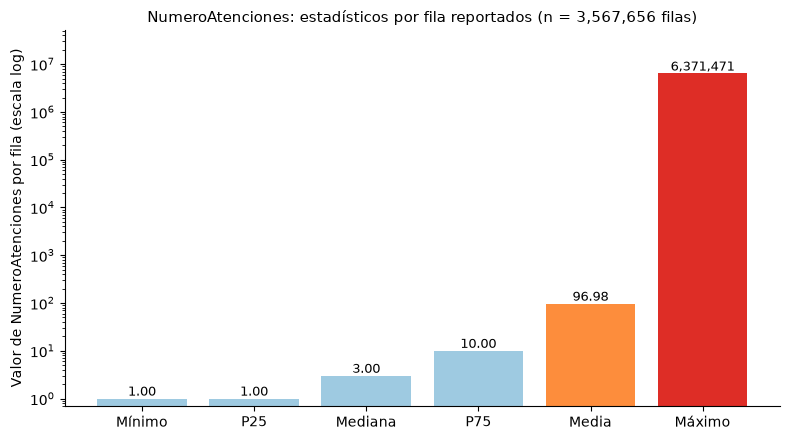

In [15]:
# Gráfica de los estadísticos reportados (escala logarítmica; todos los valores son >= 1)
etiq = ["Mínimo", "P25", "Mediana", "P75", "Media", "Máximo"]
vals = [STATS["minimo"], STATS["p25"], STATS["mediana"], STATS["p75"], STATS["media"], STATS["maximo"]]
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(etiq, vals, color=["#9ecae1"] * 4 + ["#fd8d3c", "#de2d26"])
ax.set_yscale("log")
for i, v in enumerate(vals):
    ax.text(i, v * 1.15, f"{v:,.2f}" if v < 1000 else f"{v:,.0f}", ha="center", fontsize=9)
ax.set_ylim(0.7, STATS["maximo"] * 8)
ax.set_ylabel("Valor de NumeroAtenciones por fila (escala log)")
ax.set_title("NumeroAtenciones: estadísticos por fila reportados (n = 3,567,656 filas)", fontsize=11)
fig.tight_layout()
guardar_fig(fig, "numero_atenciones_estadisticos")
plt.show()

**Interpretación prudente.**

- Todos los valores son numéricos y ≥ 1 (sin ceros ni negativos).
- La distribución por fila es **muy asimétrica a la derecha**: la media (≈97) es unas 32 veces la mediana (3), y la desviación estándar (≈7,264) es ≈75 veces la media. Como P25 = 1 coincide con el mínimo, al menos ≈25 % de las filas tiene valor 1, y ≈75 % tiene valor ≤ 10.
- El máximo (6,371,471) en una sola fila equivale a ≈1.84 % de la suma total. Si ese valor es legítimo o un atípico/error **no se puede decidir sin documentación**; no se eliminó ni se acotó.
- Que `NumeroAtenciones` sea “entero positivo” es una propiedad del formato, no una confirmación de que represente atenciones efectivamente prestadas.

### 5.4 Duplicados **[ADJUNTO]**

| Medida | Valor |
|---|---:|
| Filas excedentes por duplicado exacto (las 6 columnas) | 1,183,160 |
| Combinaciones repetidas de las 5 dimensiones | 906,363 |
| Filas excedentes por clave repetida (5 dimensiones) | 1,183,160 |

Los duplicados **no se eliminaron**.

In [16]:
# [DERIVADO] a partir de las cifras adjuntas
exc = DUP["exactos_excedentes"]
grupos = DUP["claves_repetidas_combinaciones"]
filas_en_grupos = exc + grupos  # cada grupo con c filas aporta (c-1) excedentes + 1 "original"
print(f"Filas excedentes / filas totales                    = {exc / N_FILAS * 100:.2f} %")
print(f"Filas en algún grupo repetido (clave de 5 dimensiones) = {filas_en_grupos:,} ({filas_en_grupos / N_FILAS * 100:.2f} %)")
print(f"Filas si se conservara una por grupo exacto         = {N_FILAS - exc:,}")
print(f"Coinciden excedentes exactos y excedentes por clave = {DUP['exactos_excedentes'] == DUP['claves_repetidas_filas_excedentes']}")

Filas excedentes / filas totales                    = 33.16 %
Filas en algún grupo repetido (clave de 5 dimensiones) = 2,089,523 (58.57 %)
Filas si se conservara una por grupo exacto         = 2,384,496
Coinciden excedentes exactos y excedentes por clave = True


**Lectura.**

1. Los excedentes representan ≈33.2 % de las filas; y, si se confirma la deducción del punto 2, cerca de 58.6 % de las filas pertenece a un grupo con repeticiones. Es una proporción grande y condiciona cualquier lectura de “conteo de filas”.
2. **Deducción aritmética [DERIVADO]:** como los excedentes por duplicado exacto (6 columnas) y por clave de 5 dimensiones son iguales (1,183,160), dentro de cada clave repetida los valores de `NumeroAtenciones` serían idénticos. Esto debe **confirmarse con el CSV** (celda 5.4-CSV).
**Nota de precisión:** la igualdad de los conteos excedentes NO demuestra por sí sola que todos los valores de `NumeroAtenciones` sean idénticos dentro de cada clave repetida; requiere comprobación directa con el CSV (DISTINCT `NumeroAtenciones` por clave). En modo A (sin CSV) esta afirmación debe leerse como deducción aritmética, no como comprobación directa.
3. El archivo no permite saber **por qué** existen repeticiones (carga duplicada, desagregación por una variable ausente en estas seis columnas, registros distintos con la misma clave, etc.). Son hipótesis, no hallazgos. Hasta aclararlo, filas y suma se informan **con** duplicados y se ofrece una sensibilidad sin ellos (solo con CSV).

### 5.4-CSV Verificación de duplicados y sensibilidad **[CSV]**


In [17]:
if solo_con_csv():
    cols_sql = ", ".join(f'"{c}"' for c in COLUMNAS)
    claves_sql = ", ".join(f'"{c}"' for c in DIMENSIONES)

    dup_ex = q(f"""
        SELECT count(*) AS grupos_repetidos, coalesce(sum(c - 1), 0)::BIGINT AS filas_excedentes
        FROM (SELECT count(*) AS c FROM registros GROUP BY {cols_sql} HAVING count(*) > 1)
    """)
    dup_key = q(f"""
        SELECT count(*) AS combinaciones_repetidas,
               coalesce(sum(c - 1), 0)::BIGINT AS filas_excedentes,
               count(*) FILTER (WHERE d > 1) AS combinaciones_con_NumeroAtenciones_distinto
        FROM (SELECT count(*) AS c, count(DISTINCT "NumeroAtenciones") AS d
              FROM registros GROUP BY {claves_sql} HAVING count(*) > 1)
    """)
    print("Duplicados exactos (6 columnas):");        display(dup_ex)
    print("Claves repetidas (5 dimensiones):");        display(dup_key)

    comparar("duplicados_exactos_excedentes", int(dup_ex["filas_excedentes"].iloc[0]), DUP["exactos_excedentes"])
    comparar("claves_repetidas_combinaciones", int(dup_key["combinaciones_repetidas"].iloc[0]), DUP["claves_repetidas_combinaciones"])
    comparar("claves_repetidas_filas_excedentes", int(dup_key["filas_excedentes"].iloc[0]), DUP["claves_repetidas_filas_excedentes"])

    # Sensibilidad: filas y suma si se conserva una sola fila por combinación exacta de las 6 columnas.
    # NO es "la cifra correcta": solo muestra cuánto depende el resultado de la política de duplicados.
    sens = q(f"""
        SELECT count(*) AS filas, sum(n_atenciones)::BIGINT AS suma_atenciones
        FROM (SELECT DISTINCT {cols_sql}, n_atenciones FROM v)
    """)
    comparar("filas_tras_deduplicacion_exacta", int(sens["filas"].iloc[0]), N_FILAS - DUP["exactos_excedentes"])
    sens["filas_con_duplicados"] = N_FILAS
    sens["suma_con_duplicados"] = SUMA_TOTAL
    sens["variacion_pct_filas"] = (sens["filas"] / N_FILAS - 1) * 100
    sens["variacion_pct_suma"] = (sens["suma_atenciones"] / SUMA_TOTAL - 1) * 100
    print("Sensibilidad (deduplicación exacta, solo ilustrativa):")
    display(miles(sens, ["filas", "suma_atenciones", "filas_con_duplicados", "suma_con_duplicados"])
            .assign(variacion_pct_filas=sens["variacion_pct_filas"].map("{:.2f}%".format),
                    variacion_pct_suma=sens["variacion_pct_suma"].map("{:.2f}%".format)))

Duplicados exactos (6 columnas):


,grupos_repetidos,filas_excedentes
0,906363,1183160


Claves repetidas (5 dimensiones):


,combinaciones_repetidas,filas_excedentes,combinaciones_con_NumeroAtenciones_distinto
0,906363,1183160,0


Sensibilidad (deduplicación exacta, solo ilustrativa):


,filas,suma_atenciones,filas_con_duplicados,suma_con_duplicados,variacion_pct_filas,variacion_pct_suma
0,"2,384,496","233,708,510","3,567,656","345,993,084",-33.16%,-32.45%


### 5.5 Espacios externos en `Diagnostico` **[CSV]**

Mide cuántas categorías se fusionarían al recortar espacios externos. Es solo un diagnóstico: el análisis principal conserva las etiquetas originales.

In [18]:
if solo_con_csv():
    d = q("""
        SELECT count(*) FILTER (WHERE "Diagnostico" <> trim("Diagnostico"))        AS filas_con_espacios_externos,
               count(DISTINCT "Diagnostico")                                      AS etiquetas_distintas_crudas,
               count(DISTINCT trim("Diagnostico"))                                AS etiquetas_distintas_sin_espacios_externos,
               count(DISTINCT "Diagnostico") FILTER (WHERE "Diagnostico" <> trim("Diagnostico")) AS etiquetas_crudas_con_espacios
        FROM registros
    """)
    display(miles(d))
    comparar("diagnostico_filas_con_espacios_externos", int(d["filas_con_espacios_externos"].iloc[0]), 41_794)
    comparar("diagnostico_etiquetas_distintas_crudas", int(d["etiquetas_distintas_crudas"].iloc[0]), 11_873)
    colapso = int(d["etiquetas_distintas_crudas"].iloc[0] - d["etiquetas_distintas_sin_espacios_externos"].iloc[0])
    print(f"Etiquetas que se fusionarían al recortar espacios: {colapso:,}")

,filas_con_espacios_externos,etiquetas_distintas_crudas,etiquetas_distintas_sin_espacios_externos,etiquetas_crudas_con_espacios
0,"41,794","11,873","11,873",143


Etiquetas que se fusionarían al recortar espacios: 0


## 6. Análisis univariado

### 6.1 Cardinalidad de las variables **[ADJUNTO]**

| Variable | Categorías observadas | Filas válidas (denominador) |
|---|---:|---:|
| `Departamento` | 27 | 3,567,656 |
| `Municipio` | 1,066 | 3,567,656 |
| `Año` | 1 | 3,567,656 |
| `TipoAtencion` | 4 | 3,567,656 |
| `Diagnostico` | 11,873 | 3,567,656 |

Todas las filas tienen valor en las cinco dimensiones, por lo que los porcentajes de filas usan el total (3,567,656) como denominador. Las frecuencias agrupan las cadenas **exactamente como aparecen**.

### 6.2 `TipoAtencion`: filas vs. suma de `NumeroAtenciones` **[ADJUNTO] + [DERIVADO]**

Los adjuntos reportan explícitamente solo dos de las cuatro categorías. Las otras dos **no están nombradas ni cuantificadas individualmente** en los archivos disponibles; se muestran agrupadas **por diferencia** con los totales.

,TipoAtencion,filas,suma_atenciones,pct_filas_calculado,pct_suma_calculado,suma_por_fila
0,CONSULTAS,"1,812,630","123,819,417",50.81%,35.79%,68.3
1,PROCEDIMIENTOS DE SALUD,"1,016,433","216,021,749",28.49%,62.44%,212.5
2,Otras 2 categorías (por diferencia; no nombradas en los adjuntos),"738,593","6,151,918",20.70%,1.78%,8.3


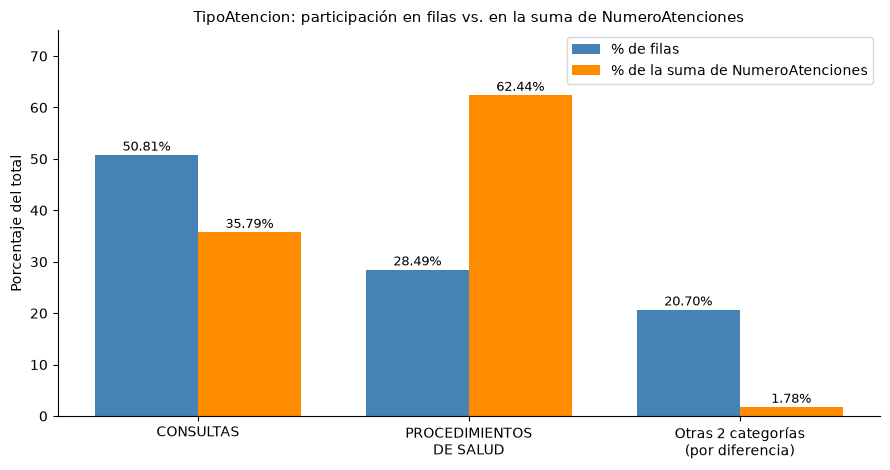

In [19]:
t = TIPO_REF.copy()
# [DERIVADO] verificación de los porcentajes reportados contra los conteos
t["pct_filas_calculado"] = t["filas"] / N_FILAS * 100
t["pct_suma_calculado"] = t["suma_atenciones"] / SUMA_TOTAL * 100
assert np.allclose(t["pct_filas_calculado"], t["pct_filas_reportado"], atol=0.005)
assert np.allclose(t["pct_suma_calculado"], t["pct_suma_reportado"], atol=0.005)

resto = pd.DataFrame([{
    "TipoAtencion": "Otras 2 categorías (por diferencia; no nombradas en los adjuntos)",
    "filas": N_FILAS - t["filas"].sum(),
    "suma_atenciones": SUMA_TOTAL - t["suma_atenciones"].sum()}])
resto["pct_filas_calculado"] = resto["filas"] / N_FILAS * 100
resto["pct_suma_calculado"] = resto["suma_atenciones"] / SUMA_TOTAL * 100

tipo_tab = pd.concat([t.drop(columns=["pct_filas_reportado", "pct_suma_reportado"]), resto], ignore_index=True)
tipo_tab["suma_por_fila"] = tipo_tab["suma_atenciones"] / tipo_tab["filas"]  # [DERIVADO] promedio de NumeroAtenciones por fila
display(miles(tipo_tab, ["filas", "suma_atenciones"]).assign(
    pct_filas_calculado=tipo_tab["pct_filas_calculado"].map("{:.2f}%".format),
    pct_suma_calculado=tipo_tab["pct_suma_calculado"].map("{:.2f}%".format),
    suma_por_fila=tipo_tab["suma_por_fila"].map("{:,.1f}".format)))

fig, ax = plt.subplots(figsize=(9, 4.8))
x = np.arange(len(tipo_tab))
w = 0.38
b1 = ax.bar(x - w / 2, tipo_tab["pct_filas_calculado"], w, label="% de filas", color="steelblue")
b2 = ax.bar(x + w / 2, tipo_tab["pct_suma_calculado"], w, label="% de la suma de NumeroAtenciones", color="darkorange")
for bars in (b1, b2):
    for r in bars:
        ax.text(r.get_x() + r.get_width() / 2, r.get_height() + 0.8, f"{r.get_height():.2f}%", ha="center", fontsize=9)
ax.set_xticks(x)
ax.set_xticklabels(["CONSULTAS", "PROCEDIMIENTOS\nDE SALUD", "Otras 2 categorías\n(por diferencia)"])
ax.set_ylabel("Porcentaje del total")
ax.set_ylim(0, 75)
ax.set_title("TipoAtencion: participación en filas vs. en la suma de NumeroAtenciones", fontsize=11)
ax.legend()
fig.tight_layout()
guardar_fig(fig, "tipo_atencion_filas_vs_suma")
plt.show()

**Interpretación prudente.**

- `CONSULTAS` es la categoría con más **filas** (50.81 %), pero aporta 35.79 % de la **suma** de `NumeroAtenciones`; `PROCEDIMIENTOS DE SALUD` tiene 28.49 % de las filas y **62.44 % de la suma**.
- Entre las dos categorías nombradas reúnen 79.3 % de las filas y 98.2 % de la suma **[DERIVADO]**; las otras dos categorías juntas son ≈20.7 % de las filas pero solo ≈1.8 % de la suma.
- El valor promedio de `NumeroAtenciones` por fila difiere mucho entre categorías (≈68 en `CONSULTAS` vs. ≈213 en `PROCEDIMIENTOS DE SALUD`). **Sin documentación no se puede saber** si refleja distinta intensidad de prestación, distinto nivel de agregación del registro o convenciones de captura. Por eso el ranking por filas y el ranking por suma no deben mezclarse.
- Faltan las dos categorías restantes (nombre, filas, suma): requieren el CSV (celda siguiente) o `frecuencias_tipoatencion.csv`.

### 6.2-CSV Frecuencias completas de `TipoAtencion` **[CSV]**

In [20]:
def frecuencia(col):
    """Frecuencia de una dimensión: filas, % filas, suma de NumeroAtenciones válida y % de suma."""
    c = f'"{col}"'
    return q(f"""
        SELECT {c} AS categoria,
               count(*)                                                  AS filas,
               count(*) * 100.0 / sum(count(*)) OVER ()                  AS pct_filas,
               count(n_atenciones)                                       AS filas_con_valor_numerico,
               sum(n_atenciones)::BIGINT                                 AS suma_atenciones,
               sum(n_atenciones) * 100.0 / sum(sum(n_atenciones)) OVER () AS pct_suma
        FROM v
        WHERE {c} IS NOT NULL AND trim({c}) <> ''
        GROUP BY {c}
        ORDER BY filas DESC, categoria
    """).rename(columns={"categoria": col})


if solo_con_csv():
    f_tipo = frecuencia("TipoAtencion")
    guardar_tabla(f_tipo, "frecuencias_tipoatencion")
    display(miles(f_tipo, ["filas", "filas_con_valor_numerico", "suma_atenciones"])
            .assign(pct_filas=f_tipo["pct_filas"].map("{:.2f}%".format), pct_suma=f_tipo["pct_suma"].map("{:.2f}%".format)))
    comparar("tipo_categorias", len(f_tipo), 4)
    comparar("tipo_filas_total", int(f_tipo["filas"].sum()), N_FILAS)
    comparar("tipo_suma_total", int(f_tipo["suma_atenciones"].sum()), SUMA_TOTAL)
    for _, r in TIPO_REF.iterrows():
        fila = f_tipo[f_tipo["TipoAtencion"] == r["TipoAtencion"]]
        if fila.empty:
            comparar(f"tipo_{r['TipoAtencion']}_presente", 0, 1)
        else:
            comparar(f"tipo_{r['TipoAtencion']}_filas", int(fila["filas"].iloc[0]), int(r["filas"]))
            comparar(f"tipo_{r['TipoAtencion']}_suma", int(fila["suma_atenciones"].iloc[0]), int(r["suma_atenciones"]))

,TipoAtencion,filas,pct_filas,filas_con_valor_numerico,suma_atenciones,pct_suma
0,CONSULTAS,"1,812,630",50.81%,"1,812,630","123,819,417",35.79%
1,PROCEDIMIENTOS DE SALUD,"1,016,433",28.49%,"1,016,433","216,021,749",62.44%
2,URGENCIAS,"401,525",11.25%,"401,525","4,024,732",1.16%
3,HOSPITALIZACIONES,"337,068",9.45%,"337,068","2,127,186",0.61%


### 6.3 `Diagnostico` **[ADJUNTO] + [CSV]**

**[ADJUNTO]** `Diagnostico` tiene 11,873 etiquetas distintas. La etiqueta con más filas es `R104 - OTROS DOLORES ABDOMINALES Y LOS NO ESPECIFICADOS` con 4,003 filas (0.112 %). Se informa como **texto observado**: no se validó contra un catálogo ni se recodificó.

In [21]:
dx, n_dx, p_dx = TOP_DX_FILAS
print(f"Etiqueta más frecuente por filas [ADJUNTO]: {dx}")
print(f"  filas = {n_dx:,} ({p_dx}% de las filas)  | recomputado: {n_dx / N_FILAS * 100:.3f}%")
print(f"[DERIVADO] filas promedio por etiqueta = {N_FILAS / 11873:,.1f}; la más frecuente = {n_dx / (N_FILAS / 11873):.1f} veces ese promedio")

Etiqueta más frecuente por filas [ADJUNTO]: R104 - OTROS DOLORES ABDOMINALES Y LOS NO ESPECIFICADOS
  filas = 4,003 (0.112% de las filas)  | recomputado: 0.112%
[DERIVADO] filas promedio por etiqueta = 300.5; la más frecuente = 13.3 veces ese promedio


**Lectura.** Como la etiqueta más frecuente concentra solo 0.112 % de las filas, **ninguna etiqueta individual supera ese porcentaje**: la distribución de filas está repartida entre muchas etiquetas. Esto debe matizarse: (i) las etiquetas con espacios externos (41,794 filas) están separadas de sus equivalentes recortadas, lo que puede fragmentar categorías (ver 5.5); (ii) el ranking por **suma** de `NumeroAtenciones` puede diferir del ranking por filas y **no está disponible en los adjuntos** (requiere `frecuencias_diagnostico.csv` o el CSV).

### 6.3-CSV Frecuencias y concentración de `Diagnostico` **[CSV]**

Etiquetas distintas: 11,873


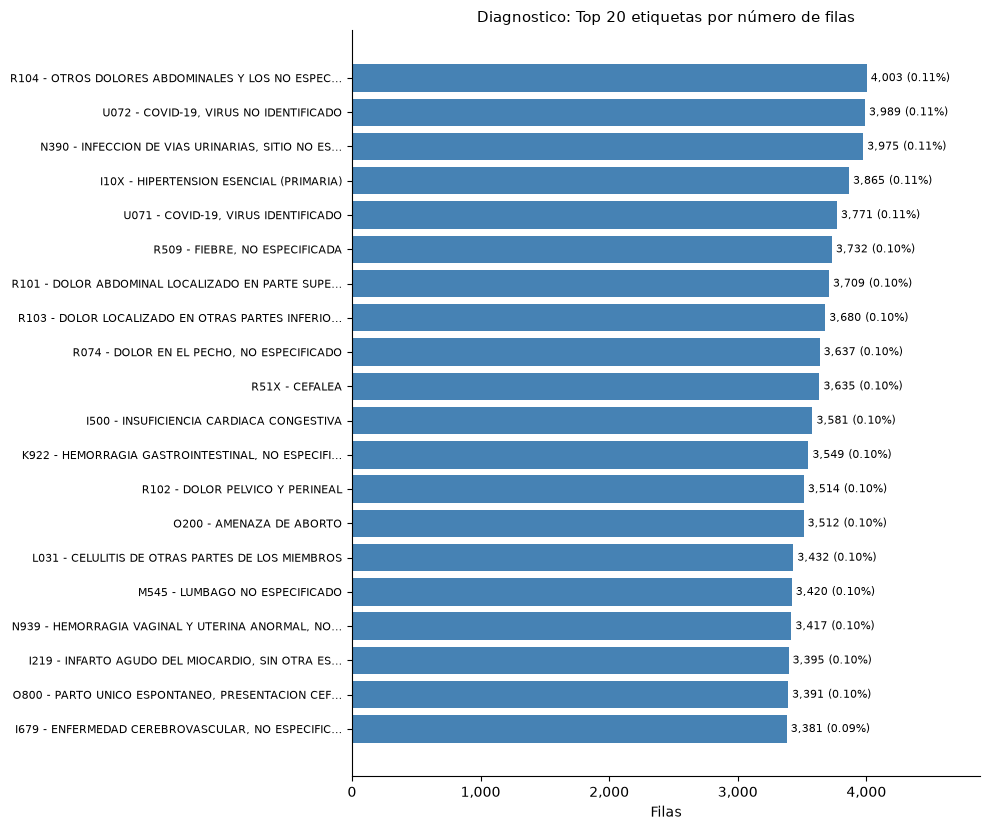

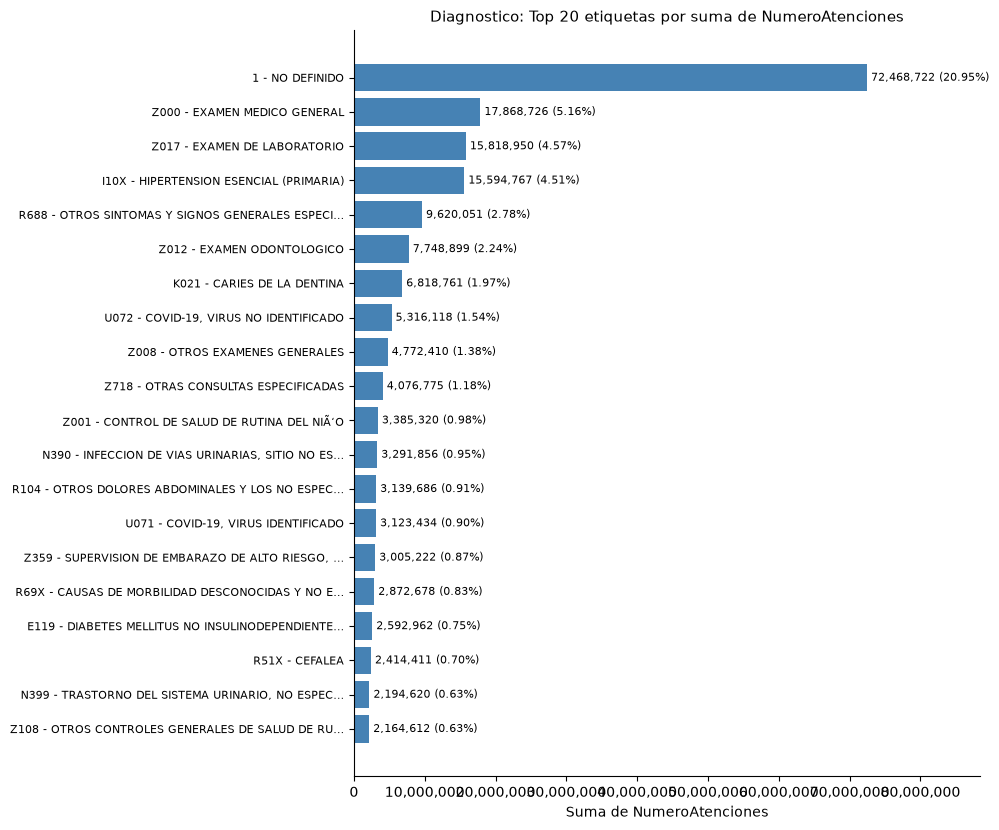

Concentración acumulada (el ranking se calcula por separado para filas y para suma):


,top_k,pct_filas_acumulado,pct_suma_acumulado
0,1,0.11,20.95
1,5,0.55,37.97
2,10,1.07,46.27
3,20,2.03,54.42
4,50,4.70,65.48
5,100,8.58,72.73


Filas cuyo Diagnostico sigue el patrón 'CÓDIGO - TEXTO' (formato observado, no catálogo validado):


,filas_con_patron_codigo_guion_texto,filas,pct
0,3567656,3567656,100.00


In [22]:
if solo_con_csv():
    f_dx = frecuencia("Diagnostico")
    guardar_tabla(f_dx, "frecuencias_diagnostico")
    print(f"Etiquetas distintas: {len(f_dx):,}")
    comparar("diagnostico_categorias", len(f_dx), 11_873)
    comparar("diagnostico_top_filas_etiqueta_coincide", f_dx["Diagnostico"].iloc[0] == TOP_DX_FILAS[0], True)
    comparar("diagnostico_top_filas_valor", int(f_dx["filas"].iloc[0]), TOP_DX_FILAS[1])

    barh_top(f_dx, "Diagnostico", "filas", f"Diagnostico: Top {TOP_N} etiquetas por número de filas",
             "Filas", col_pct="pct_filas", fname="diagnostico_top_filas")
    barh_top(f_dx, "Diagnostico", "suma_atenciones", f"Diagnostico: Top {TOP_N} etiquetas por suma de NumeroAtenciones",
             "Suma de NumeroAtenciones", col_pct="pct_suma", fname="diagnostico_top_suma")
    print("Concentración acumulada (el ranking se calcula por separado para filas y para suma):")
    display(concentracion(f_dx).round(2))

    # ¿Las etiquetas siguen el patrón "CÓDIGO - TEXTO"? (solo diagnóstico de formato; no se recodifica)
    fmt = q("""
        SELECT count(*) FILTER (WHERE regexp_matches("Diagnostico", '^\\s*\\S+\\s+-\\s+.+')) AS filas_con_patron_codigo_guion_texto,
               count(*) AS filas
        FROM registros
    """)
    fmt["pct"] = fmt["filas_con_patron_codigo_guion_texto"] / fmt["filas"] * 100
    print("Filas cuyo Diagnostico sigue el patrón 'CÓDIGO - TEXTO' (formato observado, no catálogo validado):")
    display(fmt)

### 6.4 Distribución de `NumeroAtenciones` por orden de magnitud **[CSV]**

Los adjuntos solo traen cuantiles (5.3). Para ver la forma completa de la distribución se agrupan las filas por orden de magnitud del valor (1–9, 10–99, …) y se compara la participación en filas con la participación en la suma.

,rango,filas,suma_atenciones,pct_filas,pct_suma
0,1–9,"2,654,336","6,908,710",74.40%,2.00%
1,10–99,"724,205","21,530,232",20.30%,6.22%
2,100–999,"159,070","45,278,406",4.46%,13.09%
3,"1,000–9,999","26,314","70,738,701",0.74%,20.45%
4,"10,000–99,999","3,425","90,638,677",0.10%,26.20%
5,"100,000–999,999",283,"61,612,844",0.01%,17.81%
6,"1,000,000–9,999,999",23,"49,285,514",0.00%,14.24%


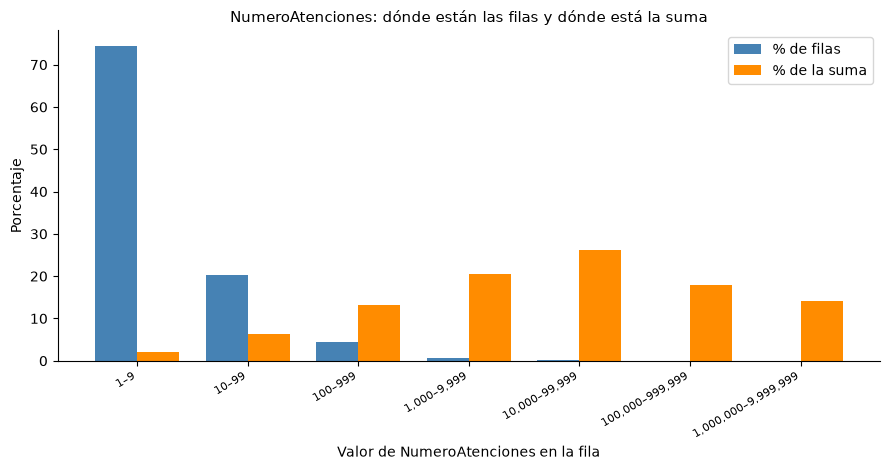

In [23]:
if solo_con_csv():
    mag = q("""
        SELECT floor(log10(n_atenciones))::INTEGER AS exp10,
               count(*) AS filas,
               sum(n_atenciones)::BIGINT AS suma_atenciones
        FROM v WHERE n_atenciones > 0
        GROUP BY 1 ORDER BY 1
    """)
    mag["rango"] = mag["exp10"].map(lambda e: f"{10**e:,}–{10**(e + 1) - 1:,}")
    mag["pct_filas"] = mag["filas"] / mag["filas"].sum() * 100
    mag["pct_suma"] = mag["suma_atenciones"] / mag["suma_atenciones"].sum() * 100
    guardar_tabla(mag, "distribucion_numero_atenciones_por_magnitud")
    display(miles(mag[["rango", "filas", "suma_atenciones"]]).assign(
        pct_filas=mag["pct_filas"].map("{:.2f}%".format), pct_suma=mag["pct_suma"].map("{:.2f}%".format)))

    fig, ax = plt.subplots(figsize=(9, 4.8))
    x = np.arange(len(mag)); w = 0.38
    ax.bar(x - w / 2, mag["pct_filas"], w, label="% de filas", color="steelblue")
    ax.bar(x + w / 2, mag["pct_suma"], w, label="% de la suma", color="darkorange")
    ax.set_xticks(x); ax.set_xticklabels(mag["rango"], rotation=30, ha="right", fontsize=8)
    ax.set_xlabel("Valor de NumeroAtenciones en la fila"); ax.set_ylabel("Porcentaje")
    ax.set_title("NumeroAtenciones: dónde están las filas y dónde está la suma", fontsize=11)
    ax.legend(); fig.tight_layout(); guardar_fig(fig, "numero_atenciones_magnitud"); plt.show()

    # Estadísticos recalculados vs. adjuntos
    est = q("""
        SELECT count(n_atenciones) AS validos,
               count(*) FILTER (WHERE n_atenciones IS NULL AND trim(coalesce("NumeroAtenciones", '')) <> '') AS no_convertibles,
               count(*) FILTER (WHERE n_atenciones = 0) AS ceros,
               count(*) FILTER (WHERE n_atenciones < 0) AS negativos,
               min(n_atenciones) AS minimo, max(n_atenciones) AS maximo,
               sum(n_atenciones)::BIGINT AS suma, avg(n_atenciones) AS media,
               median(n_atenciones) AS mediana,
               quantile_cont(n_atenciones, 0.25) AS p25, quantile_cont(n_atenciones, 0.75) AS p75,
               stddev_samp(n_atenciones) AS desv_estandar
        FROM v
    """).iloc[0]
    comparar("na_validos", int(est["validos"]), STATS["valores_numericos_validos"])
    comparar("na_no_convertibles", int(est["no_convertibles"]), STATS["no_convertibles_no_vacios"])
    comparar("na_ceros", int(est["ceros"]), STATS["valores_cero"])
    comparar("na_negativos", int(est["negativos"]), STATS["valores_negativos"])
    comparar("na_minimo", int(est["minimo"]), STATS["minimo"])
    comparar("na_maximo", int(est["maximo"]), STATS["maximo"])
    comparar("na_suma", int(est["suma"]), STATS["suma"])
    comparar("na_media", float(est["media"]), STATS["media"], tol=1e-6)
    comparar("na_mediana", float(est["mediana"]), STATS["mediana"], tol=1e-9)
    comparar("na_p25", float(est["p25"]), STATS["p25"], tol=1e-9)
    comparar("na_p75", float(est["p75"]), STATS["p75"], tol=1e-9)
    comparar("na_desv_estandar", float(est["desv_estandar"]), STATS["desviacion_estandar_muestral"], tol=1e-4)

## 7. Análisis geográfico

`Departamento` y `Municipio` se tratan como **etiquetas geográficas del registro**. No se afirma que representen residencia del paciente, ocurrencia del evento ni lugar de prestación del servicio: el archivo no lo indica y la documentación local no lo define.

### 7.1 Alcance geográfico y etiquetas líderes **[ADJUNTO]**

| Medida | Valor | Fuente |
|---|---|---|
| Etiquetas de `Departamento` distintas | 27 | adjunto |
| Etiquetas de `Municipio` distintas | 1,066 | adjunto |
| `Departamento` con más filas | `25 - Cundinamarca` — 468,637 filas (13.14 %) | adjunto |
| `Municipio` con mayor suma de `NumeroAtenciones` | `11001 - Bogotá, D.C.` — 42,305,118 | adjunto |

In [24]:
d_lab, d_filas, d_pct = TOP_DPTO_FILAS
m_lab, m_suma = TOP_MPIO_SUMA
print(f"Departamento líder por FILAS [ADJUNTO]: {d_lab} -> {d_filas:,} filas ({d_pct}%)  | recomputado {d_filas / N_FILAS * 100:.2f}%")
print(f"Municipio líder por SUMA   [ADJUNTO]: {m_lab} -> {m_suma:,}  | {m_suma / SUMA_TOTAL * 100:.2f}% de la suma total [DERIVADO]")
print("Nota: los dos líderes se miden con criterios distintos (filas vs. suma) y en niveles distintos (departamento vs. municipio); no son comparables entre sí.")

Departamento líder por FILAS [ADJUNTO]: 25 - Cundinamarca -> 468,637 filas (13.14%)  | recomputado 13.14%
Municipio líder por SUMA   [ADJUNTO]: 11001 - Bogotá, D.C. -> 42,305,118  | 12.23% de la suma total [DERIVADO]
Nota: los dos líderes se miden con criterios distintos (filas vs. suma) y en niveles distintos (departamento vs. municipio); no son comparables entre sí.


**Interpretación prudente.**

- Los dos hallazgos geográficos adjuntos usan métricas diferentes (filas para departamento; suma para municipio). Los adjuntos **no incluyen** el ranking completo, ni el municipio líder por filas, ni el departamento líder por suma, por lo que **no se puede construir un ranking geográfico completo sin el CSV**.
- Los valores absolutos por territorio no son tasas: sin población u otro denominador no se puede comparar “intensidad” entre territorios. Un territorio grande tendrá más filas y más suma simplemente por tamaño.
- Se observan **27** etiquetas de departamento. Antes de afirmar cobertura territorial nacional, conviene listar las 27 etiquetas (celda 7.2) y contrastarlas con el listado oficial de entidades territoriales que se use como referencia.
- Las etiquetas observadas tienen la forma `código - nombre` (p. ej. `25 - Cundinamarca`, `11001 - Bogotá, D.C.`). Esto es una observación sobre texto, no una validación de códigos.

### 7.2 Frecuencias geográficas completas **[CSV]**

Las 27 etiquetas de Departamento observadas:


,Departamento
0,-1 - NO DEFINIDO
1,05 - Antioquia
2,08 - AtlÃ¡ntico
3,"11 - BogotÃ¡, D.C."
4,13 - BolÃ­var
5,15 - BoyacÃ¡
6,17 - Caldas
7,18 - CaquetÃ¡
8,19 - Cauca
9,20 - Cesar


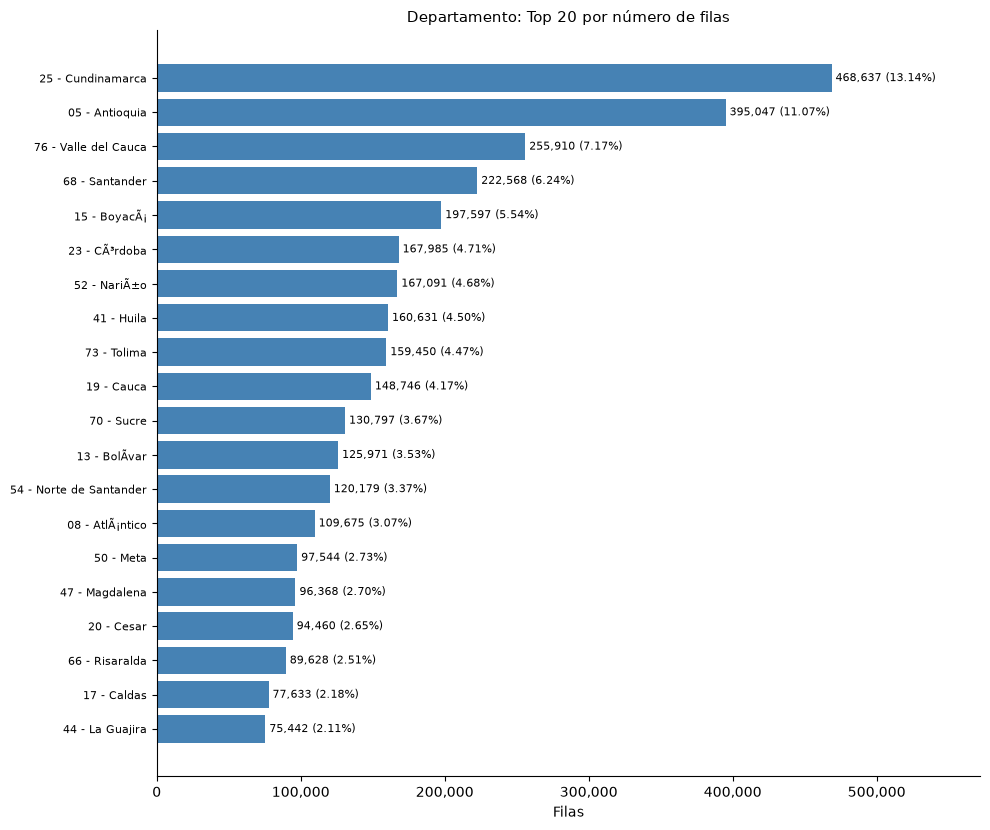

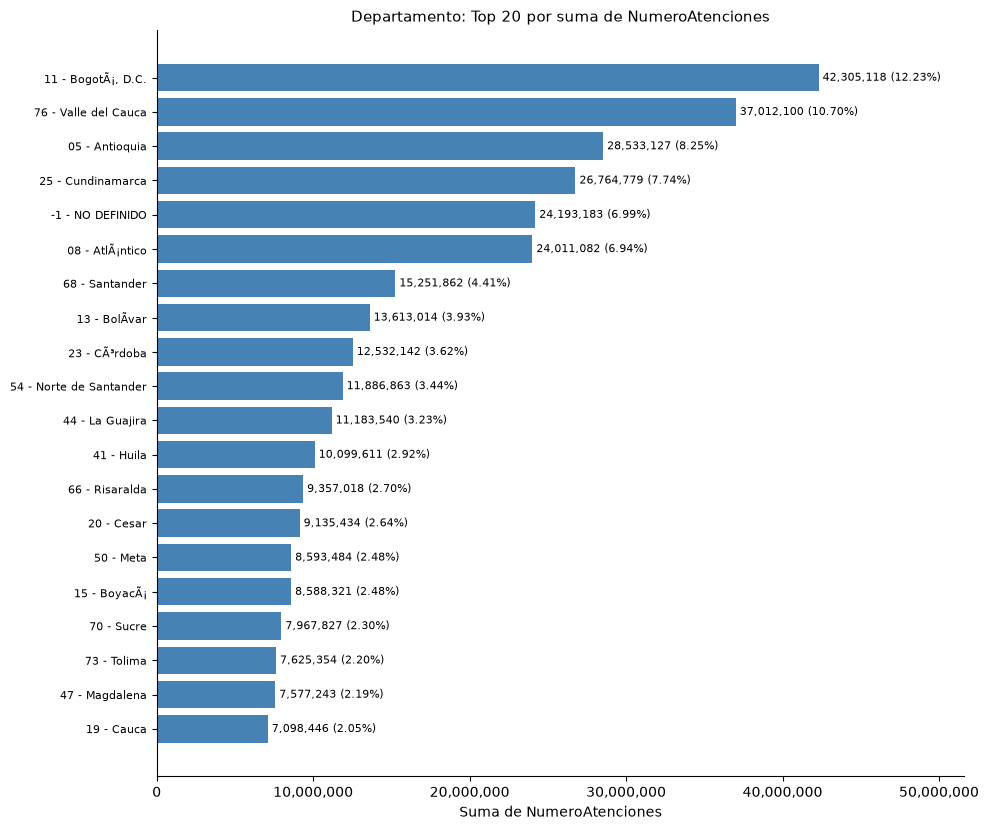

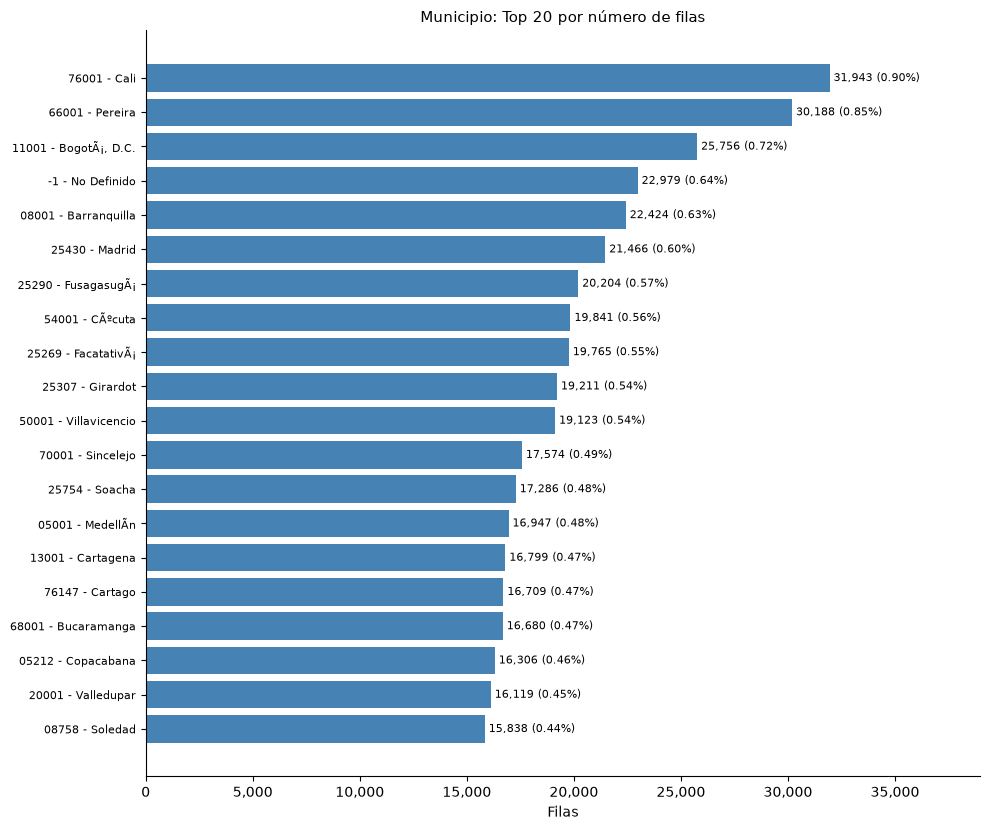

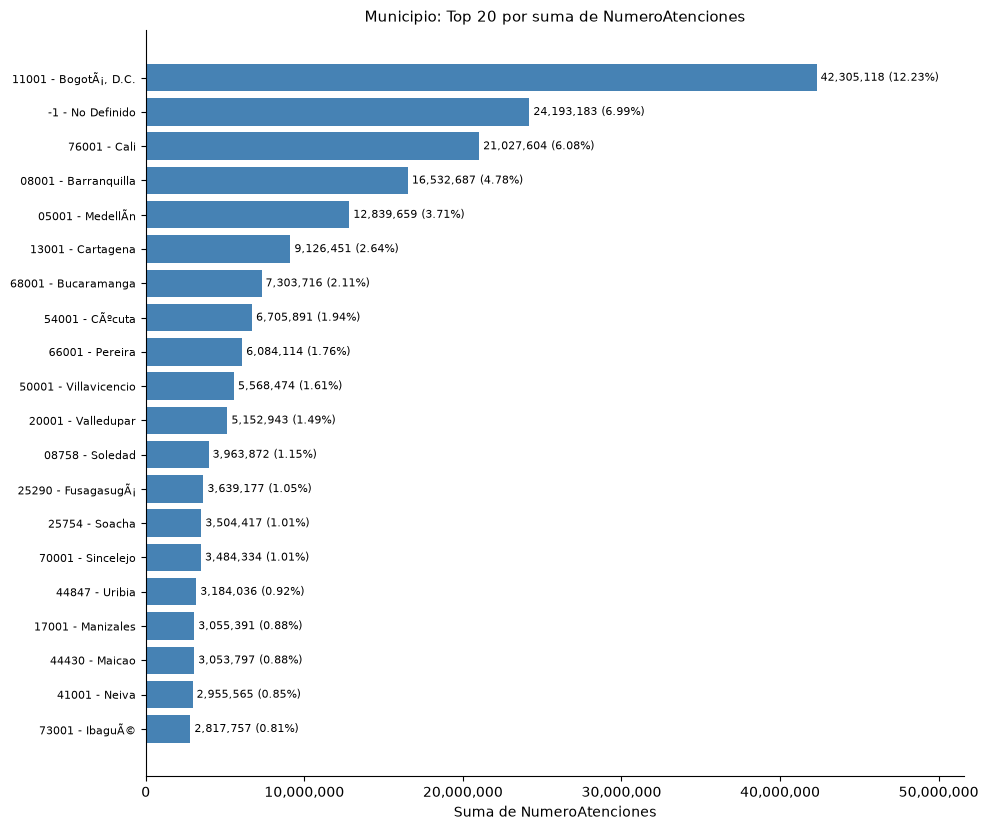

Concentración geográfica acumulada — Departamento:


,top_k,pct_filas_acumulado,pct_suma_acumulado
0,1,13.14,12.23
1,3,31.38,31.17
2,5,43.16,45.90
3,10,65.69,68.24


Concentración geográfica acumulada — Municipio:


,top_k,pct_filas_acumulado,pct_suma_acumulado
0,1,0.90,12.23
1,5,3.74,33.79
2,10,6.55,43.84
3,20,11.30,53.90
4,50,22.09,68.48
5,100,34.04,77.96


In [25]:
if solo_con_csv():
    f_dpto = frecuencia("Departamento")
    f_mpio = frecuencia("Municipio")
    guardar_tabla(f_dpto, "frecuencias_departamento")
    guardar_tabla(f_mpio, "frecuencias_municipio")

    comparar("departamento_categorias", len(f_dpto), 27)
    comparar("municipio_categorias", len(f_mpio), 1_066)
    comparar("departamento_top_filas_etiqueta_coincide", f_dpto["Departamento"].iloc[0] == TOP_DPTO_FILAS[0], True)
    comparar("departamento_top_filas_valor", int(f_dpto["filas"].iloc[0]), TOP_DPTO_FILAS[1])
    top_m_suma = f_mpio.sort_values("suma_atenciones", ascending=False).iloc[0]
    comparar("municipio_top_suma_etiqueta_coincide", top_m_suma["Municipio"] == TOP_MPIO_SUMA[0], True)
    comparar("municipio_top_suma_valor", int(top_m_suma["suma_atenciones"]), TOP_MPIO_SUMA[1])

    print("Las 27 etiquetas de Departamento observadas:")
    display(f_dpto[["Departamento"]].sort_values("Departamento").reset_index(drop=True))

    barh_top(f_dpto, "Departamento", "filas", f"Departamento: Top {TOP_N} por número de filas", "Filas",
             col_pct="pct_filas", fname="departamento_top_filas")
    barh_top(f_dpto, "Departamento", "suma_atenciones", f"Departamento: Top {TOP_N} por suma de NumeroAtenciones",
             "Suma de NumeroAtenciones", col_pct="pct_suma", fname="departamento_top_suma")
    barh_top(f_mpio, "Municipio", "filas", f"Municipio: Top {TOP_N} por número de filas", "Filas",
             col_pct="pct_filas", fname="municipio_top_filas")
    barh_top(f_mpio, "Municipio", "suma_atenciones", f"Municipio: Top {TOP_N} por suma de NumeroAtenciones",
             "Suma de NumeroAtenciones", col_pct="pct_suma", fname="municipio_top_suma")

    print("Concentración geográfica acumulada — Departamento:")
    display(concentracion(f_dpto, ks=(1, 3, 5, 10)).round(2))
    print("Concentración geográfica acumulada — Municipio:")
    display(concentracion(f_mpio, ks=(1, 5, 10, 20, 50, 100)).round(2))

### 7.3 Coherencia interna `Municipio` ↔ `Departamento` **[CSV]**

Dos revisiones exploratorias sobre las propias etiquetas del archivo, sin tablas externas:

1. ¿Algún `Municipio` aparece asociado a más de un `Departamento`?
2. Si ambas etiquetas siguen el formato `código - nombre` con códigos numéricos, ¿los dos primeros dígitos del código de municipio coinciden con el código de departamento? Esta segunda revisión **presupone una convención de codificación** (códigos municipales que comienzan con el código del departamento) que no está documentada en los adjuntos; sus resultados son indicios para revisar, no errores confirmados.

In [26]:
if solo_con_csv():
    multi = q("""
        SELECT "Municipio", count(DISTINCT "Departamento") AS n_departamentos, count(*) AS filas
        FROM registros GROUP BY "Municipio" HAVING count(DISTINCT "Departamento") > 1
        ORDER BY filas DESC
    """)
    print(f"Municipios asociados a más de un Departamento: {len(multi):,}")
    if len(multi):
        display(multi.head(20))

    pref = q("""
        WITH t AS (
            SELECT "Departamento" AS dpto, "Municipio" AS mun,
                   split_part("Departamento", ' - ', 1) AS cod_dpto,
                   split_part("Municipio", ' - ', 1)    AS cod_mun
            FROM registros
        )
        SELECT count(*) AS filas_evaluadas,
               count(*) FILTER (WHERE left(cod_mun, 2) <> cod_dpto) AS filas_prefijo_no_coincide
        FROM t
        WHERE regexp_matches(cod_dpto, '^[0-9]+$') AND regexp_matches(cod_mun, '^[0-9]+$')
    """)
    pref["filas_no_evaluables"] = N_FILAS - pref["filas_evaluadas"]
    display(miles(pref))
    if int(pref["filas_prefijo_no_coincide"].iloc[0]) > 0:
        display(q("""
            WITH t AS (
                SELECT "Departamento" AS dpto, "Municipio" AS mun,
                       split_part("Departamento", ' - ', 1) AS cod_dpto,
                       split_part("Municipio", ' - ', 1)    AS cod_mun
                FROM registros
            )
            SELECT dpto, mun, count(*) AS filas
            FROM t
            WHERE regexp_matches(cod_dpto, '^[0-9]+$') AND regexp_matches(cod_mun, '^[0-9]+$')
              AND left(cod_mun, 2) <> cod_dpto
            GROUP BY dpto, mun ORDER BY filas DESC LIMIT 20
        """))

Municipios asociados a más de un Departamento: 0


,filas_evaluadas,filas_prefijo_no_coincide,filas_no_evaluables
0,"3,544,677",0,"22,979"


## 8. Cruces descriptivos

Los cruces describen asociaciones entre etiquetas; **no son causales** ni permiten inferir comportamiento poblacional.

### 8.1 Inventario de cruces **[ADJUNTO] + [DERIVADO]**

`resumen_hallazgos.md` reporta, para cada cruce, el número de combinaciones observadas. La cobertura relativa se obtiene dividiendo por el máximo teórico (producto de las cardinalidades de cada variable).

In [27]:
card = {"Departamento": 27, "Municipio": 1066, "TipoAtencion": 4, "Diagnostico": 11873}
c = CRUCES_REF.copy()
c["combinaciones_posibles"] = c.apply(lambda r: card[r["var_a"]] * card[r["var_b"]], axis=1)  # [DERIVADO]
c["cobertura_pct"] = c["combinaciones_observadas"] / c["combinaciones_posibles"] * 100          # [DERIVADO]
c["filas_por_combinacion_promedio"] = N_FILAS / c["combinaciones_observadas"]                    # [DERIVADO]
display(miles(c, ["combinaciones_observadas", "combinaciones_posibles"]).assign(
    cobertura_pct=c["cobertura_pct"].map("{:.1f}%".format),
    filas_por_combinacion_promedio=c["filas_por_combinacion_promedio"].map("{:,.1f}".format)))

,cruce,var_a,var_b,combinaciones_observadas,combinaciones_posibles,cobertura_pct,filas_por_combinacion_promedio
0,cruce_departamento_tipo_atencion,Departamento,TipoAtencion,108,108,100.0%,"33,033.9"
1,cruce_tipo_atencion_diagnostico,TipoAtencion,Diagnostico,"39,011","47,492",82.1%,91.5
2,cruce_departamento_diagnostico,Departamento,Diagnostico,"199,406","320,571",62.2%,17.9
3,cruce_municipio_tipo_atencion,Municipio,TipoAtencion,"4,255","4,264",99.8%,838.5


**Lectura.**

- `Departamento × TipoAtencion`: se observan las 108 combinaciones posibles (27 × 4); todos los departamentos tienen filas en los cuatro tipos.
- `Municipio × TipoAtencion`: 4,255 de 4,264 posibles (99.8 %); solo 9 combinaciones no aparecen.
- `TipoAtencion × Diagnostico`: 82.1 % de cobertura; `Departamento × Diagnostico`: 62.2 %. La cobertura menor indica que no todas las etiquetas de diagnóstico aparecen en todos los departamentos (o tipos); el motivo no se puede determinar con los adjuntos.
- En los cuatro cruces, las filas por combinación suman 3,567,656 y la suma de `NumeroAtenciones` conserva 345,993,084 (controles 8–11 y 23–30 de la validación técnica).

### 8.2 Qué no se puede construir solo con los adjuntos

Los archivos `cruce_*.csv` **no fueron entregados**; solo se dispone de sus tamaños y de los controles de conservación de totales. Por tanto, **sin el CSV no es posible** reportar: qué departamentos concentran cada `TipoAtencion`, los diagnósticos principales por tipo, ni los pares departamento–diagnóstico más frecuentes. Las siguientes celdas los calculan en modo B y se omiten en modo A.

### 8.3 Cruces completos **[CSV]**

In [28]:
def cruce(a, b):
    """Cruce descriptivo a x b con filas y suma de NumeroAtenciones, usando solo pares completos."""
    ca, cb = f'"{a}"', f'"{b}"'
    return q(f"""
        SELECT {ca} AS "{a}", {cb} AS "{b}",
               count(*) AS filas,
               count(*) * 100.0 / sum(count(*)) OVER () AS pct_filas,
               sum(n_atenciones)::BIGINT AS suma_atenciones,
               sum(n_atenciones) * 100.0 / sum(sum(n_atenciones)) OVER () AS pct_suma
        FROM v
        WHERE {ca} IS NOT NULL AND trim({ca}) <> '' AND {cb} IS NOT NULL AND trim({cb}) <> ''
        GROUP BY {ca}, {cb}
        ORDER BY filas DESC
    """)


if solo_con_csv():
    cruces = {}
    for _, r in CRUCES_REF.iterrows():
        df_c = cruce(r["var_a"], r["var_b"])
        cruces[r["cruce"]] = df_c
        guardar_tabla(df_c, r["cruce"])
        comparar(f"{r['cruce']}_combinaciones", len(df_c), int(r["combinaciones_observadas"]))
        comparar(f"{r['cruce']}_filas", int(df_c["filas"].sum()), N_FILAS)
        comparar(f"{r['cruce']}_suma", int(df_c["suma_atenciones"].sum()), SUMA_TOTAL)
    print({k: len(v) for k, v in cruces.items()})

{'cruce_departamento_tipo_atencion': 108, 'cruce_tipo_atencion_diagnostico': 39011, 'cruce_departamento_diagnostico': 199406, 'cruce_municipio_tipo_atencion': 4255}


#### 8.3.1 `Departamento` × `TipoAtencion` **[CSV]**

Composición de cada departamento por tipo de atención, medida por separado en filas y en suma de `NumeroAtenciones`. Como en 6.2 las dos medidas pueden contar historias distintas.

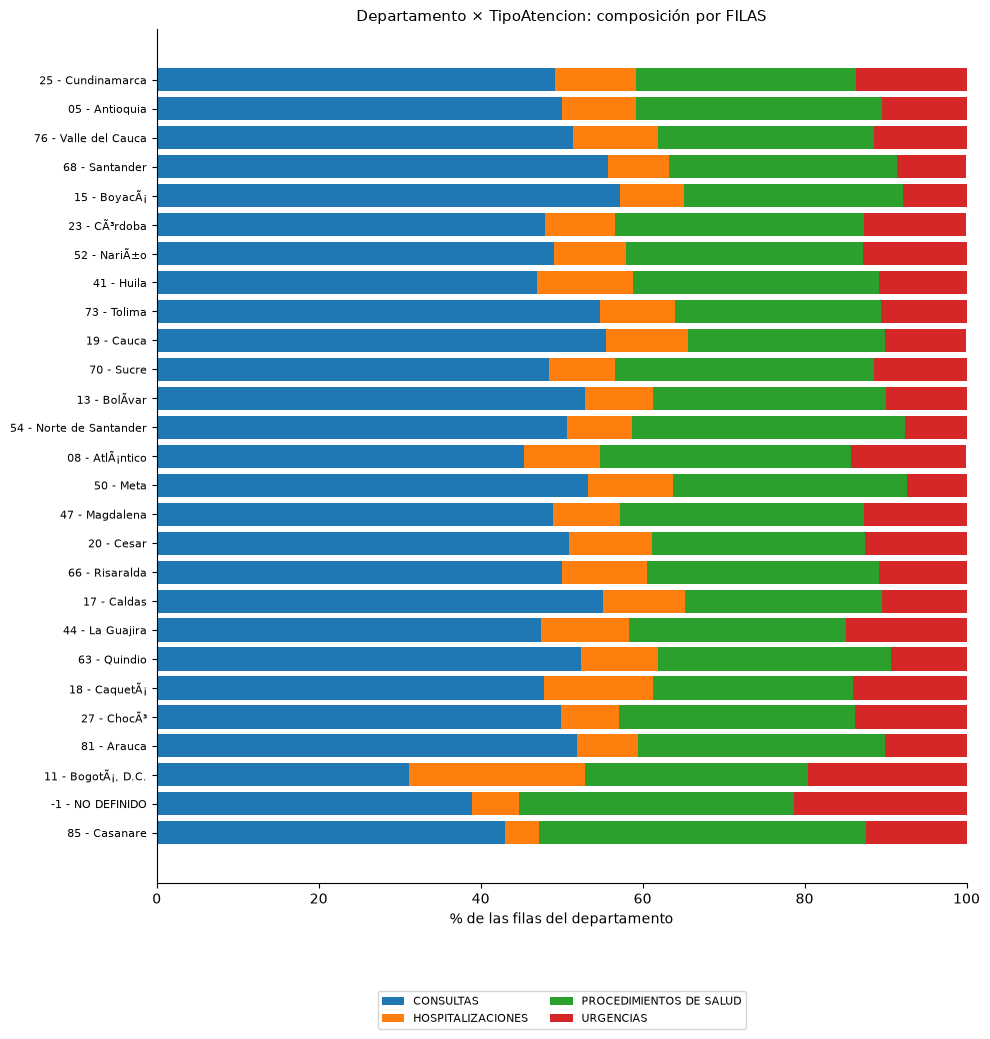

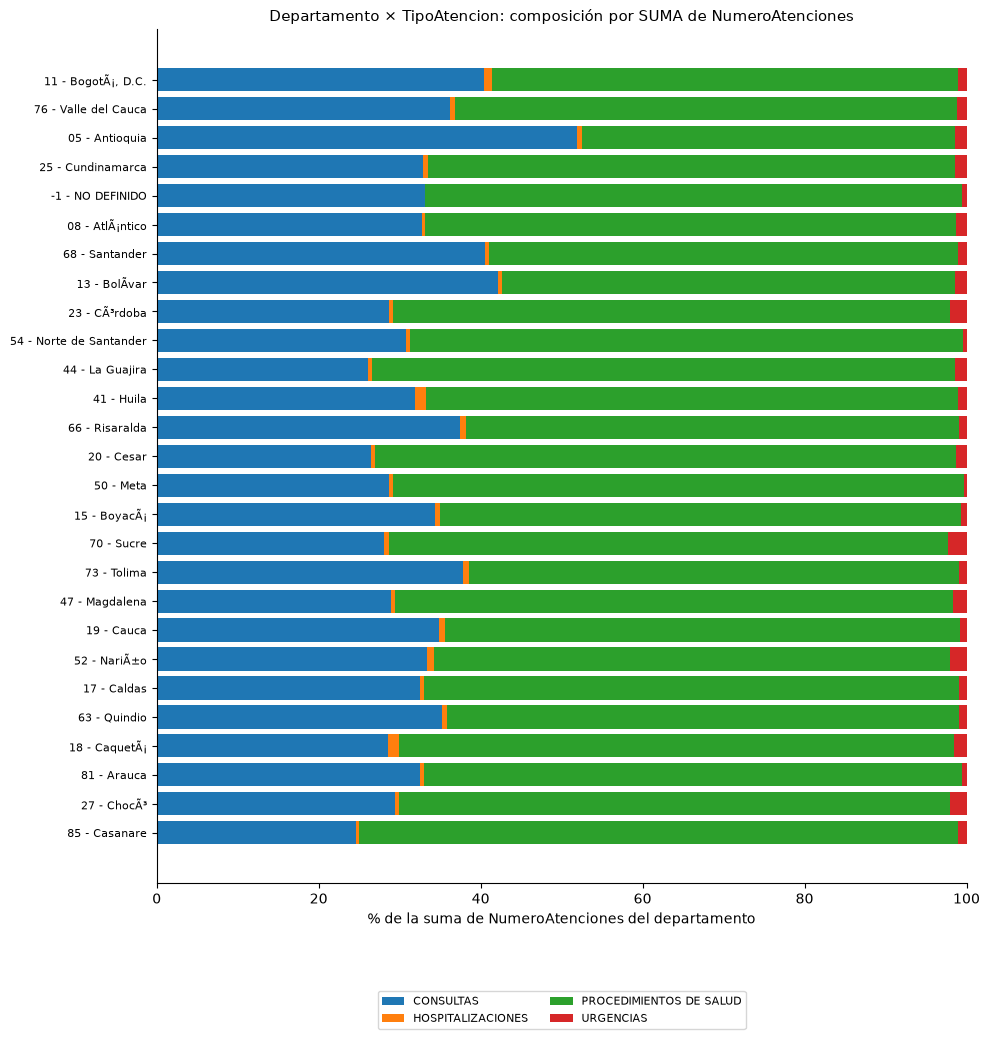

In [29]:
if solo_con_csv():
    dt = cruces["cruce_departamento_tipo_atencion"]
    apilado_100(dt, "Departamento", "TipoAtencion", "filas",
                "Departamento × TipoAtencion: composición por FILAS", "% de las filas del departamento",
                fname="cruce_dpto_tipo_filas")
    apilado_100(dt, "Departamento", "TipoAtencion", "suma_atenciones",
                "Departamento × TipoAtencion: composición por SUMA de NumeroAtenciones",
                "% de la suma de NumeroAtenciones del departamento", fname="cruce_dpto_tipo_suma")

#### 8.3.2 `TipoAtencion` × `Diagnostico`: principales etiquetas por tipo **[CSV]**

In [30]:
if solo_con_csv():
    td = cruces["cruce_tipo_atencion_diagnostico"]
    for tipo, g in td.groupby("TipoAtencion"):
        print(f"\n{tipo} — Top 5 diagnósticos por filas")
        display(miles(g.nlargest(5, "filas")[["Diagnostico", "filas", "suma_atenciones"]], ["filas", "suma_atenciones"]))
        print(f"{tipo} — Top 5 diagnósticos por suma de NumeroAtenciones")
        display(miles(g.nlargest(5, "suma_atenciones")[["Diagnostico", "filas", "suma_atenciones"]], ["filas", "suma_atenciones"]))


CONSULTAS — Top 5 diagnósticos por filas


,Diagnostico,filas,suma_atenciones
0,I10X - HIPERTENSION ESENCIAL (PRIMARIA),"1,105","8,358,945"
1,Z349 - SUPERVISION DE EMBARAZO NORMAL NO ESPECIFICADO,"1,071","314,931"
2,"Z359 - SUPERVISION DE EMBARAZO DE ALTO RIESGO, SIN OTRA ESPECIFICA...","1,067","1,241,925"
4,R104 - OTROS DOLORES ABDOMINALES Y LOS NO ESPECIFICADOS,"1,051","1,241,755"
5,E109 - DIABETES MELLITUS INSULINODEPENDIENTE SIN MENCION DE COMPLI...,"1,048","563,876"


CONSULTAS — Top 5 diagnósticos por suma de NumeroAtenciones


,Diagnostico,filas,suma_atenciones
0,I10X - HIPERTENSION ESENCIAL (PRIMARIA),"1,105","8,358,945"
20,Z000 - EXAMEN MEDICO GENERAL,"1,027","4,814,634"
221,Z718 - OTRAS CONSULTAS ESPECIFICADAS,926,"3,719,898"
106,R688 - OTROS SINTOMAS Y SIGNOS GENERALES ESPECIFICADOS,981,"3,287,847"
30,Z012 - EXAMEN ODONTOLOGICO,"1,016","2,800,627"



HOSPITALIZACIONES — Top 5 diagnósticos por filas


...

,Diagnostico,filas,suma_atenciones
26,1 - NO DEFINIDO,"1,019","72,468,722"
96,Z017 - EXAMEN DE LABORATORIO,984,"15,513,589"
57,Z000 - EXAMEN MEDICO GENERAL,"1,003","13,037,142"
176,I10X - HIPERTENSION ESENCIAL (PRIMARIA),946,"7,138,697"
74,R688 - OTROS SINTOMAS Y SIGNOS GENERALES ESPECIFICADOS,993,"6,298,696"



URGENCIAS — Top 5 diagnósticos por filas


,Diagnostico,filas,suma_atenciones
124,I10X - HIPERTENSION ESENCIAL (PRIMARIA),972,"72,604"
161,"N390 - INFECCION DE VIAS URINARIAS, SITIO NO ESPECIFICADO",952,"112,070"
167,"U072 - COVID-19, VIRUS NO IDENTIFICADO",950,"174,413"
199,R104 - OTROS DOLORES ABDOMINALES Y LOS NO ESPECIFICADOS,935,"164,290"
207,"R509 - FIEBRE, NO ESPECIFICADA",932,"130,268"


URGENCIAS — Top 5 diagnósticos por suma de NumeroAtenciones


,Diagnostico,filas,suma_atenciones
167,"U072 - COVID-19, VIRUS NO IDENTIFICADO",950,"174,413"
199,R104 - OTROS DOLORES ABDOMINALES Y LOS NO ESPECIFICADOS,935,"164,290"
207,"R509 - FIEBRE, NO ESPECIFICADA",932,"130,268"
286,R51X - CEFALEA,901,"117,285"
161,"N390 - INFECCION DE VIAS URINARIAS, SITIO NO ESPECIFICADO",952,"112,070"


#### 8.3.3 `Departamento` × `Diagnostico` y `Municipio` × `TipoAtencion` **[CSV]**

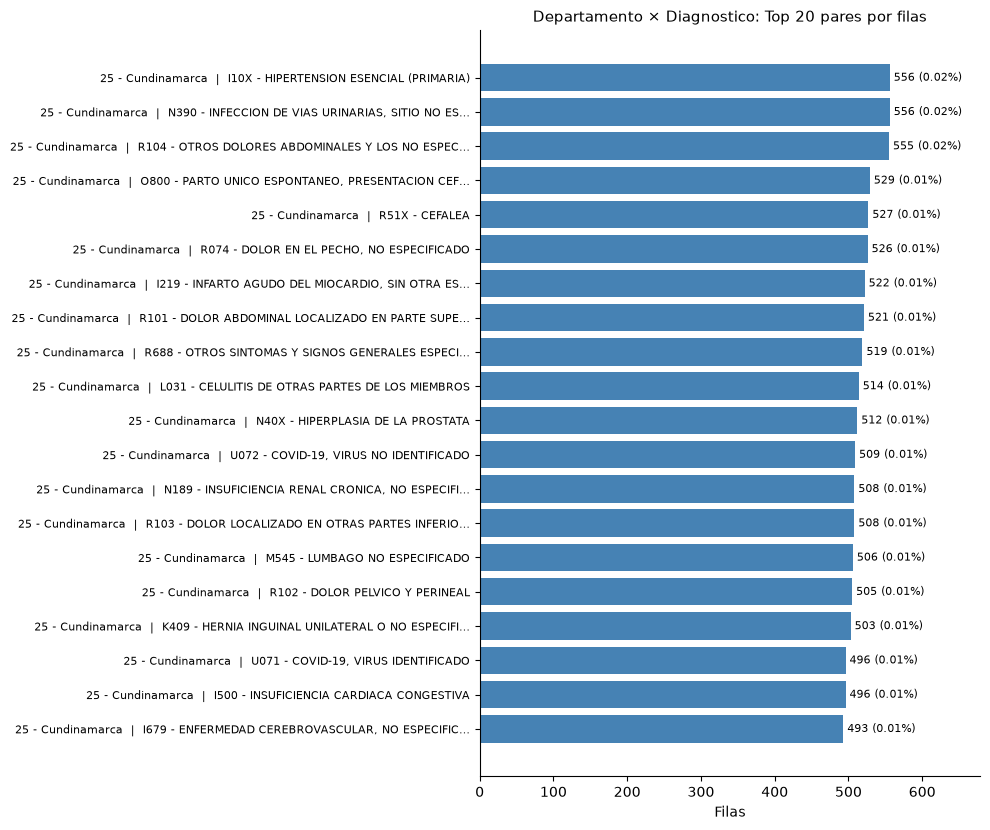

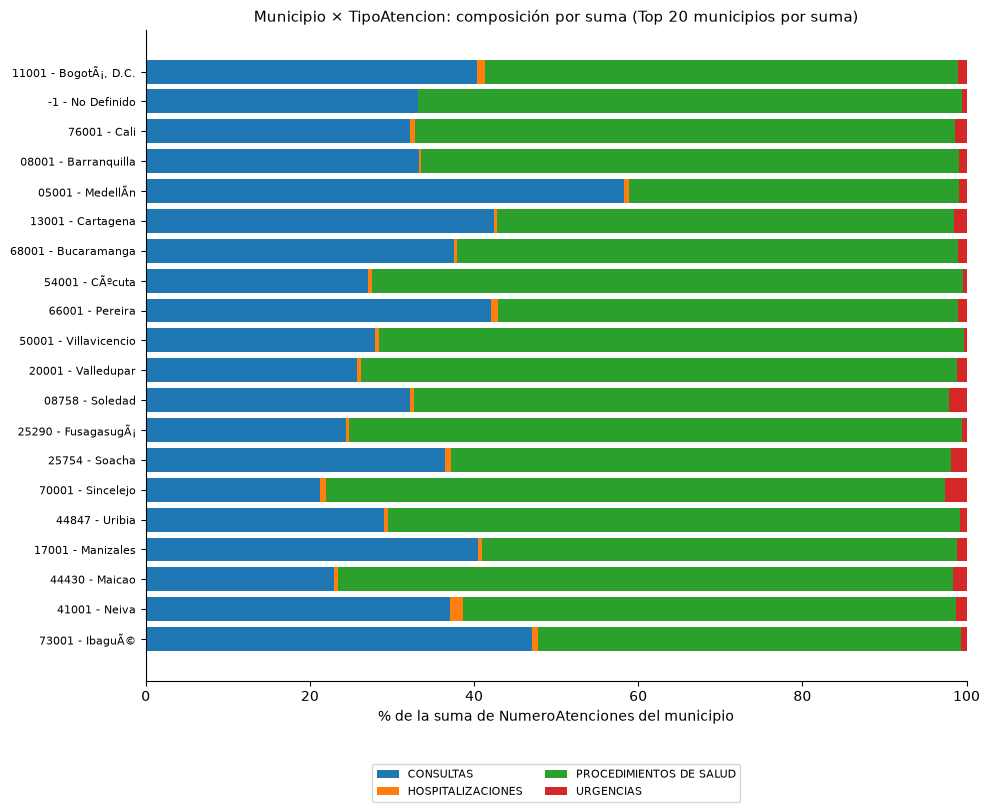

In [31]:
if solo_con_csv():
    dd = cruces["cruce_departamento_diagnostico"]
    top_pares = dd.nlargest(TOP_N, "filas").copy()
    top_pares["par"] = top_pares["Departamento"] + "  |  " + top_pares["Diagnostico"].str.strip()
    barh_top(top_pares, "par", "filas", f"Departamento × Diagnostico: Top {TOP_N} pares por filas", "Filas",
             col_pct="pct_filas", fname="cruce_dpto_dx_top_filas", wrap=70)

    mt = cruces["cruce_municipio_tipo_atencion"]
    tot_m = mt.groupby("Municipio")["suma_atenciones"].sum().nlargest(TOP_N).index
    apilado_100(mt[mt["Municipio"].isin(tot_m)], "Municipio", "TipoAtencion", "suma_atenciones",
                f"Municipio × TipoAtencion: composición por suma (Top {TOP_N} municipios por suma)",
                "% de la suma de NumeroAtenciones del municipio", fname="cruce_mpio_tipo_suma_top")

## 9. Verificaciones: comprobaciones técnicas vs. validación semántica

### 9.1 Las 30 comprobaciones reportadas **[ADJUNTO]**

`validacion_totales.csv` contiene 30 controles, todos con resultado `OK`. Se clasifican según qué comprueban.

In [32]:
def clase_control(nombre):
    if nombre.startswith("lectura_"):
        return "Lectura vs. conteo previo"
    if nombre == "numero_atenciones_particion":
        return "Partición de NumeroAtenciones (válidos + no convertibles + vacíos)"
    if nombre.startswith("frecuencia_"):
        return "Denominador de frecuencias (suma de filas = no vacíos)"
    if nombre.startswith("cruce_"):
        return "Denominador de cruces (suma de filas = pares completos)"
    if nombre.startswith("suma_numericos_"):
        return "Conservación de filas con valor numérico en tablas agregadas"
    if nombre.startswith("suma_atenciones_"):
        return "Conservación de la suma de NumeroAtenciones en tablas agregadas"
    return "Otro"

val = VALIDACION.assign(clase=VALIDACION["control"].map(clase_control))
val["coincide_observado_esperado"] = val["observado"] == val["esperado"]
resumen_val = (val.groupby("clase")
               .agg(controles=("control", "count"),
                    todos_OK=("resultado", lambda s: bool((s == "OK").all())),
                    observado_igual_esperado=("coincide_observado_esperado", "all"))
               .reset_index().sort_values("controles", ascending=False))
display(resumen_val)
print("Total de controles:", len(val), "| con resultado OK:", int((val['resultado'] == 'OK').sum()))
assert len(val) == 30 and val["clase"].ne("Otro").all()

,clase,controles,todos_OK,observado_igual_esperado
1,Conservación de la suma de NumeroAtenciones en tablas agregadas,10,True,True
0,Conservación de filas con valor numérico en tablas agregadas,9,True,True
3,Denominador de frecuencias (suma de filas = no vacíos),5,True,True
2,Denominador de cruces (suma de filas = pares completos),4,True,True
4,Lectura vs. conteo previo,1,True,True
5,Partición de NumeroAtenciones (válidos + no convertibles + vacíos),1,True,True


Total de controles: 30 | con resultado OK: 30


**Qué demuestran y qué no.**

- Demuestran **consistencia técnica interna**: la lectura es reproducible, los agregados no pierden ni duplican filas, y las sumas se conservan al agrupar por cualquier dimensión o par de dimensiones.
- **No** demuestran que las etiquetas sean correctas, que `NumeroAtenciones` mida atenciones, que los códigos pertenezcan a un catálogo oficial, que la cobertura territorial sea completa ni que los duplicados sean errores o registros legítimos.
- Varios controles son de tipo “la suma de las partes es el total”: se cumplen por construcción de una agregación correcta y detectarían un error de código, pero no un problema de contenido. Por ello **no deben presentarse como certificación oficial de los datos**; son la validación técnica del procesamiento. La validación semántica sigue pendiente (requiere diccionario, catálogos y la fuente).

### 9.2 Conciliación del CSV local con los adjuntos **[CSV]**

Cada cifra recalculada en las celdas **[CSV]** se compara con su valor adjunto. “SÍ” indica que el recálculo reproduce el adjunto; no agrega validez semántica.

In [33]:
if solo_con_csv():
    conc = pd.DataFrame(RECONC)
    display(conc)
    n_no = int((conc["coincide"] == "NO").sum())
    print(f"Comparaciones: {len(conc)} | coinciden: {len(conc) - n_no} | difieren: {n_no}")
    if n_no:
        print("ATENCIÓN: hay diferencias con lo adjunto. Revise versión del CSV, lectura (codificación/delimitador) y duplicados.")
    guardar_tabla(conc, "conciliacion_csv_vs_adjuntos")
else:
    print("Modo A: no hay recálculo que conciliar. Las cifras de este notebook provienen de los adjuntos.")

,control,recalculado_csv,valor_adjunto,coincide
0,filas_totales,3567656,3567656,SÍ
1,columnas,6,6,SÍ
2,duplicados_exactos_excedentes,1183160,1183160,SÍ
3,claves_repetidas_combinaciones,906363,906363,SÍ
4,claves_repetidas_filas_excedentes,1183160,1183160,SÍ
5,filas_tras_deduplicacion_exacta,2384496,2384496,SÍ
6,diagnostico_filas_con_espacios_externos,41794,41794,SÍ
7,diagnostico_etiquetas_distintas_crudas,11873,11873,SÍ
8,tipo_categorias,4,4,SÍ
9,tipo_filas_total,3567656,3567656,SÍ


Comparaciones: 48 | coinciden: 47 | difieren: 1
ATENCIÓN: hay diferencias con lo adjunto. Revise versión del CSV, lectura (codificación/delimitador) y duplicados.


## 10. Conclusiones, limitaciones y recomendaciones

### 10.1 Resultados respaldados (observados en los adjuntos)

1. **Tamaño y estructura.** 3,567,656 filas × 6 columnas; sin nulos, vacíos ni valores solo-espacios; `Año` = 2021 único. *[ADJUNTO]*
2. **`NumeroAtenciones`.** Enteros positivos (mín. 1, máx. 6,371,471), suma 345,993,084, media ≈96.98, mediana 3, P25 = 1, P75 = 10. Distribución muy asimétrica; un solo valor máximo equivale a ≈1.84 % de la suma. *[ADJUNTO] + [DERIVADO]*
3. **Duplicados.** 1,183,160 filas excedentes (≈33.2 %); 906,363 combinaciones de las cinco dimensiones están repetidas. Las filas y la suma se informan con duplicados. *[ADJUNTO] + [DERIVADO]*
4. **`Diagnostico`.** 11,873 etiquetas, 41,794 filas con espacios externos; la etiqueta más frecuente por filas (`R104 - OTROS DOLORES ABDOMINALES Y LOS NO ESPECIFICADOS`) reúne solo 0.112 % de las filas. *[ADJUNTO]*
5. **`TipoAtencion`.** Cuatro categorías; `CONSULTAS` lidera en filas (50.81 %) y `PROCEDIMIENTOS DE SALUD` en suma (62.44 %). Filas y suma ofrecen lecturas distintas. *[ADJUNTO]*
6. **Geografía.** 27 etiquetas de departamento y 1,066 de municipio; `25 - Cundinamarca` es el departamento con más filas (13.14 %) y `11001 - Bogotá, D.C.` el municipio con mayor suma (42,305,118, ≈12.2 % del total). *[ADJUNTO] + [DERIVADO]*
7. **Cruces.** `Departamento × TipoAtencion` cubre las 108 combinaciones posibles; los cuatro cruces conservan filas y suma. *[ADJUNTO]*
8. **Controles técnicos.** 30 de 30 comprobaciones de consistencia aprobadas. *[ADJUNTO]*

### 10.2 Limitaciones

- **Sin diccionario**: significado de columnas, unidad de observación y de `NumeroAtenciones` no confirmados; la suma **no** es un total oficial de prestaciones.
- **Geografía**: no se sabe si es residencia, ocurrencia o lugar de prestación.
- **Duplicados** de causa desconocida que afectan filas y suma (33 % de las filas son excedentes).
- **Diagnósticos y tipos** sin validar contra catálogos; etiquetas con espacios pueden fragmentar categorías.
- **Un solo año**: no hay tendencias ni estacionalidad.
- **Sin denominadores** (población, afiliados): no hay tasas ni comparaciones de intensidad entre territorios.
- **Con los adjuntos únicamente** no se pudo construir: ranking completo por departamento/municipio/diagnóstico, nombres y cifras de las otras dos categorías de `TipoAtencion`, ni el contenido de los cruces. Esas secciones se calculan en modo B.
- Las asociaciones son descriptivas, **no causales**.

### 10.3 Recomendaciones para análisis posteriores

1. Obtener el diccionario de datos y la definición de la unidad de observación y de `NumeroAtenciones`.
2. Determinar el origen de los duplicados y definir una política explícita (conservar, deduplicar o colapsar), con análisis de sensibilidad (ver 5.4-CSV).
3. Normalizar `Diagnostico` (espacios; separación código/texto) y validarlo contra el catálogo correspondiente, si existe.
4. Revisar los valores extremos de `NumeroAtenciones` antes de usar sumas o promedios (por ejemplo con medianas o percentiles).
5. Definir con la fuente qué representa la geografía y verificar cobertura frente a un listado oficial de territorios.
6. Incorporar denominadores poblacionales solo si la definición geográfica lo permite; hasta entonces, evitar tasas.
7. Si se dispone de otros años, repetir el EDA para evaluar comparabilidad antes de analizar tendencias.

### 10.4 Qué requiere ejecutar el CSV local

| Sección | Modo A (adjuntos) | Modo B (CSV) |
|---|---|---|
| 4.1, 5.1–5.3, 5.4 (cifras), 6.1, 6.2 (2 de 4 categorías), 6.3 (etiqueta líder), 7.1, 8.1, 9.1 | Sí | — |
| 3 (carga), 4.2 | No | Sí |
| 5.4-CSV (verificación y sensibilidad), 5.5 | No | Sí |
| 6.2-CSV, 6.3-CSV, 6.4 | No | Sí |
| 7.2, 7.3 | No | Sí |
| 8.3 (cruces completos y gráficos) | No | Sí |
| 9.2 (conciliación) | No | Sí |

Las tablas completas (`frecuencias_*.csv`, `cruce_*.csv`, `conciliacion_csv_vs_adjuntos.csv`) y las figuras se guardan en la carpeta indicada por `RIPS_OUT_DIR`.